CELL 1 — Imports, setup, Google Drive, dan konfigurasi

In [2]:
!pip install -q keras-tuner

In [3]:
from google.colab import drive, files
drive.mount('/content/drive')

import os, zipfile, shutil, random, json, time, gc, hashlib, datetime, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2, VGG16
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint,
    TensorBoard, BackupAndRestore, CSVLogger
)
from tensorflow.keras.mixed_precision import set_global_policy

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score,
    top_k_accuracy_score
)
import keras_tuner as kt

warnings.filterwarnings("ignore")
ImageFile.LOAD_TRUNCATED_IMAGES = False

# ---------- Penyimpanan permanen ----------
DRIVE_PATH = "/content/drive/MyDrive/hasil_model_revisi2a"
DIRS = {
    "dataset": os.path.join(DRIVE_PATH, "dataset"),
    "split": os.path.join(DRIVE_PATH, "split_dataset"),
    "models": os.path.join(DRIVE_PATH, "models"),
    "checkpoints": os.path.join(DRIVE_PATH, "checkpoints"),
    "tuner": os.path.join(DRIVE_PATH, "tuner_results"),
    "logs": os.path.join(DRIVE_PATH, "logs"),
    "results": os.path.join(DRIVE_PATH, "results"),
    "exports": os.path.join(DRIVE_PATH, "exports")
}
for p in DIRS.values():
    os.makedirs(p, exist_ok=True)

# ---------- Reproducibility ----------
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Aktifkan mixed precision untuk kedua model secara konsisten.
# Jika muncul masalah numerik/kompatibilitas, ubah menjadi "float32" untuk KEDUA model.
COMPUTE_POLICY = "mixed_float16"
set_global_policy(COMPUTE_POLICY)

# ---------- Anggaran eksperimen yang sama ----------
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16                 # Sama untuk kedua model
TUNER_TRIALS = 10
TUNER_EPOCHS = 3
TUNER_STEPS = 100               # Sama untuk kedua model
TUNER_VALIDATION_STEPS = None   # None = seluruh validation set
PHASE1_EPOCHS = 15
PHASE2_EPOCHS = 20
TUNER_PATIENCE = 2
EARLY_STOP_PATIENCE_P1 = 5
EARLY_STOP_PATIENCE_P2 = 6

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Compute policy:", tf.keras.mixed_precision.global_policy())
print("Folder hasil:", DRIVE_PATH)

# Mengurangi risiko alokasi memori GPU sekaligus.
for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except Exception as e:
        print("Memory growth tidak diubah:", e)

Mounted at /content/drive
TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Compute policy: <DTypePolicy "mixed_float16">
Folder hasil: /content/drive/MyDrive/hasil_model_revisi2a


CELL 2 — Upload atau gunakan kembali ZIP dataset

In [4]:
# Jika ZIP sudah ada di Google Drive, isi ZIP_PATH dengan path tersebut.
# Jika dikosongkan/tidak ditemukan, notebook akan meminta upload.
ZIP_PATH = os.path.join(DRIVE_PATH, "dataset_original.zip")

if not os.path.exists(ZIP_PATH):
    print("Upload file ZIP dataset.")
    uploaded = files.upload()
    if not uploaded:
        raise RuntimeError("Tidak ada file ZIP yang diunggah.")
    uploaded_name = next(iter(uploaded))
    if not uploaded_name.lower().endswith(".zip"):
        raise ValueError("File yang diunggah harus berformat .zip")
    shutil.copy2(uploaded_name, ZIP_PATH)

BASE_PATH = "/content/dataset"
if os.path.exists(BASE_PATH):
    shutil.rmtree(BASE_PATH)
os.makedirs(BASE_PATH, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(BASE_PATH)

print("Dataset diekstrak ke:", BASE_PATH)
print("Isi folder:", os.listdir(BASE_PATH)[:30])

Dataset diekstrak ke: /content/dataset
Isi folder: ['ds_new']


CELL 3 — Pemeriksaan struktur folder, cleaning, dan pencatatan distribusi

In [8]:
VALID_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

def flatten_single_root(path):
    # Hilangkan satu atau lebih folder pembungkus jika hanya berisi satu subfolder.
    while True:
        items = [x for x in os.listdir(path) if x not in ("__MACOSX",)]
        if len(items) == 1 and os.path.isdir(os.path.join(path, items[0])):
            inner = os.path.join(path, items[0])
            for item in os.listdir(inner):
                shutil.move(os.path.join(inner, item), path)
            shutil.rmtree(inner)
        else:
            break

def class_distribution(path):
    out = {}
    for cls in sorted(os.listdir(path)):
        cpath = os.path.join(path, cls)
        if os.path.isdir(cpath):
            out[cls] = sum(
                1 for f in os.listdir(cpath)
                if f.lower().endswith(VALID_EXT) and os.path.isfile(os.path.join(cpath, f))
            )
    return out

flatten_single_root(BASE_PATH)
dist_before_cleaning = class_distribution(BASE_PATH)
print("Distribusi sebelum cleaning:", dist_before_cleaning)
print("Total sebelum cleaning:", sum(dist_before_cleaning.values()))

removed_corrupt = 0
for cls in os.listdir(BASE_PATH):
    class_dir = os.path.join(BASE_PATH, cls)
    if not os.path.isdir(class_dir):
        continue
    for fname in list(os.listdir(class_dir)):
        fpath = os.path.join(class_dir, fname)
        if os.path.isdir(fpath):
            continue
        if not fname.lower().endswith(VALID_EXT):
            continue
        try:
            if os.path.getsize(fpath) == 0:
                raise ValueError("Empty file")
            with Image.open(fpath) as im:
                im.verify()
        except Exception:
            if os.path.isfile(fpath):
                os.remove(fpath)
                removed_corrupt += 1

flatten_single_root(BASE_PATH)
dist_after_cleaning = class_distribution(BASE_PATH)
print("File rusak/non-valid dihapus:", removed_corrupt)
print("Distribusi setelah cleaning:", dist_after_cleaning)
print("Total setelah cleaning:", sum(dist_after_cleaning.values()))

cleaning_table = pd.DataFrame({
    "Class": sorted(set(dist_before_cleaning) | set(dist_after_cleaning))
})
cleaning_table["Before cleaning"] = cleaning_table["Class"].map(dist_before_cleaning).fillna(0).astype(int)
cleaning_table["After cleaning"] = cleaning_table["Class"].map(dist_after_cleaning).fillna(0).astype(int)
cleaning_table["Removed"] = cleaning_table["Before cleaning"] - cleaning_table["After cleaning"]
display(cleaning_table)
cleaning_table.to_csv(os.path.join(DIRS["results"], "dataset_cleaning_distribution.csv"), index=False)

Distribusi sebelum cleaning: {'B3': 1000, 'Kaca': 1108, 'Kardus': 1013, 'Kertas': 1806, 'Logam': 1210, 'Medis': 1227, 'Plastik': 1257, 'nonsampah': 9200, 'organik': 1364}
Total sebelum cleaning: 19185
File rusak/non-valid dihapus: 0
Distribusi setelah cleaning: {'B3': 1000, 'Kaca': 1108, 'Kardus': 1013, 'Kertas': 1806, 'Logam': 1210, 'Medis': 1227, 'Plastik': 1257, 'nonsampah': 9200, 'organik': 1364}
Total setelah cleaning: 19185


,Class,Before cleaning,After cleaning,Removed
0,B3,1000,1000,0
1,Kaca,1108,1108,0
2,Kardus,1013,1013,0
3,Kertas,1806,1806,0
4,Logam,1210,1210,0
5,Medis,1227,1227,0
6,Plastik,1257,1257,0
7,nonsampah,9200,9200,0
8,organik,1364,1364,0


Audit duplikat lintas kelas (tanpa mengubah dataset)
Cell ini harus dijalankan setelah Cell 3 (cleaning) dan sebelum Cell 4 (deduplikasi). Tujuannya hanya mendeteksi gambar identik yang muncul pada label kelas berbeda. Cell ini tidak menghapus, memindahkan, atau mengubah file apa pun.

In [9]:
# AUDIT NON-DESTRUKTIF: exact duplicate yang muncul pada lebih dari satu kelas
from collections import defaultdict

_hash_locations = defaultdict(list)

for _cls in sorted(os.listdir(BASE_PATH)):
    _class_dir = os.path.join(BASE_PATH, _cls)
    if not os.path.isdir(_class_dir):
        continue
    for _fname in sorted(os.listdir(_class_dir)):
        _fpath = os.path.join(_class_dir, _fname)
        if not os.path.isfile(_fpath) or not _fname.lower().endswith(VALID_EXT):
            continue
        try:
            with open(_fpath, "rb") as _fh:
                _digest = hashlib.md5(_fh.read()).hexdigest()
            _hash_locations[_digest].append({
                "Class": _cls,
                "Filename": _fname,
                "Path": _fpath
            })
        except Exception as _err:
            print(f"Gagal membaca {_fpath}: {_err}")

_cross_class_rows = []
_same_class_duplicate_groups = 0

for _digest, _items in _hash_locations.items():
    _classes = sorted(set(x["Class"] for x in _items))
    if len(_items) > 1 and len(_classes) == 1:
        _same_class_duplicate_groups += 1
    if len(_classes) > 1:
        for _item in _items:
            _cross_class_rows.append({
                "MD5": _digest,
                "Class": _item["Class"],
                "Filename": _item["Filename"],
                "Path": _item["Path"],
                "Classes_sharing_same_image": " | ".join(_classes)
            })

df_cross_class_duplicates = pd.DataFrame(_cross_class_rows)
print("Jumlah kelompok MD5 yang memiliki duplikat dalam kelas yang sama:",
      _same_class_duplicate_groups)
print("Jumlah file yang terlibat dalam duplikat lintas kelas:",
      len(df_cross_class_duplicates))

if not df_cross_class_duplicates.empty:
    display(df_cross_class_duplicates)
    print("PERHATIAN: periksa label pada file-file berikut sebelum menyimpulkan deduplikasi aman.")
else:
    print("Tidak ditemukan exact duplicate lintas kelas pada dataset yang diperiksa.")

_cross_dup_path = os.path.join(DIRS["results"], "cross_class_duplicate_audit.csv")
df_cross_class_duplicates.to_csv(_cross_dup_path, index=False)
print("Laporan audit disimpan:", _cross_dup_path)


Jumlah kelompok MD5 yang memiliki duplikat dalam kelas yang sama: 4231
Jumlah file yang terlibat dalam duplikat lintas kelas: 0
Tidak ditemukan exact duplicate lintas kelas pada dataset yang diperiksa.
Laporan audit disimpan: /content/drive/MyDrive/hasil_model_revisi2a/results/cross_class_duplicate_audit.csv


CELL 4 — Deduplikasi MD5 exact match dan distribusi akhir

In [10]:
print("=" * 70)
print("DEDUplikasi MD5 EXACT MATCH")
print("=" * 70)

seen_hashes = {}
duplicates_removed = 0
duplicates_per_class = Counter()

for cls in sorted(os.listdir(BASE_PATH)):
    class_dir = os.path.join(BASE_PATH, cls)
    if not os.path.isdir(class_dir):
        continue
    for fname in sorted(os.listdir(class_dir)):
        fpath = os.path.join(class_dir, fname)
        if not os.path.isfile(fpath) or not fname.lower().endswith(VALID_EXT):
            continue
        try:
            with open(fpath, "rb") as f:
                digest = hashlib.md5(f.read()).hexdigest()
        except Exception:
            continue

        if digest in seen_hashes:
            os.remove(fpath)
            duplicates_removed += 1
            duplicates_per_class[cls] += 1
        else:
            seen_hashes[digest] = fpath

dist_after_dedup = class_distribution(BASE_PATH)
print("Duplikat exact dihapus:", duplicates_removed)
print("Duplikat per kelas:", dict(duplicates_per_class))
print("Distribusi setelah deduplikasi:", dist_after_dedup)
print("Total akhir:", sum(dist_after_dedup.values()))

final_distribution = pd.DataFrame({
    "Class": sorted(dist_after_dedup),
    "Images after deduplication": [dist_after_dedup[c] for c in sorted(dist_after_dedup)]
})
display(final_distribution)
final_distribution.to_csv(os.path.join(DIRS["results"], "dataset_final_distribution.csv"), index=False)

# Simpan ringkasan cleaning agar dapat dilaporkan secara transparan.
dataset_audit = {
    "zip_path": ZIP_PATH,
    "initial_distribution": dist_before_cleaning,
    "after_cleaning_distribution": dist_after_cleaning,
    "after_deduplication_distribution": dist_after_dedup,
    "corrupt_or_invalid_removed": int(removed_corrupt),
    "exact_duplicates_removed": int(duplicates_removed),
    "duplicates_removed_per_class": dict(duplicates_per_class)
}
with open(os.path.join(DIRS["results"], "dataset_audit.json"), "w") as f:
    json.dump(dataset_audit, f, indent=2)

DEDUplikasi MD5 EXACT MATCH
Duplikat exact dihapus: 6446
Duplikat per kelas: {'B3': 40, 'Logam': 1, 'Medis': 23, 'Plastik': 1, 'nonsampah': 5606, 'organik': 775}
Distribusi setelah deduplikasi: {'B3': 960, 'Kaca': 1108, 'Kardus': 1013, 'Kertas': 1806, 'Logam': 1209, 'Medis': 1204, 'Plastik': 1256, 'nonsampah': 3594, 'organik': 589}
Total akhir: 12739


,Class,Images after deduplication
0,B3,960
1,Kaca,1108
2,Kardus,1013
3,Kertas,1806
4,Logam,1209
5,Medis,1204
6,Plastik,1256
7,nonsampah,3594
8,organik,589


CELL 4B — [Reviewer B] Tabel distribusi kelas sebelum & sesudah cleaning + deduplikasi

,Class,Original,After corrupt removal,After duplicate removal (final),Corrupt removed,Duplicates removed,Total removed,Removed (%),Original share (%),Final share (%)
0,B3,1000,1000,960,0,40,40,4.00,5.21,7.54
1,Kaca,1108,1108,1108,0,0,0,0.00,5.78,8.70
2,Kardus,1013,1013,1013,0,0,0,0.00,5.28,7.95
3,Kertas,1806,1806,1806,0,0,0,0.00,9.41,14.18
4,Logam,1210,1210,1209,0,1,1,0.08,6.31,9.49
5,Medis,1227,1227,1204,0,23,23,1.87,6.40,9.45
6,Plastik,1257,1257,1256,0,1,1,0.08,6.55,9.86
7,nonsampah,9200,9200,3594,0,5606,5606,60.93,47.95,28.21
8,organik,1364,1364,589,0,775,775,56.82,7.11,4.62
9,TOTAL,19185,19185,12739,0,6446,6446,33.60,100.00,100.00


Imbalance ratio sebelum cleaning : 9.20 : 1
Imbalance ratio sesudah dedup    : 6.10 : 1
Total gambar: 19185 -> 12739  (dihapus 6446, 33.60%)


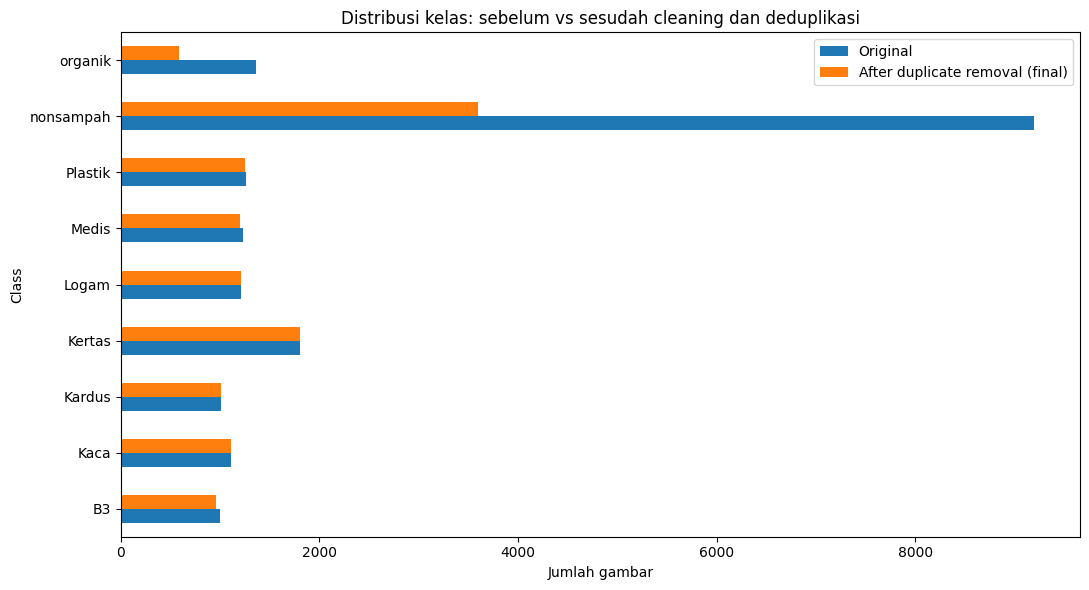

In [11]:
# Menggabungkan hasil Cell 3 dan Cell 4 menjadi satu tabel yang siap masuk paper.
classes_all = sorted(set(dist_before_cleaning) | set(dist_after_dedup))
tot_orig = sum(dist_before_cleaning.values())
tot_final = sum(dist_after_dedup.values())

rows = []
for c in classes_all:
    orig = dist_before_cleaning.get(c, 0)
    clean = dist_after_cleaning.get(c, 0)
    final = dist_after_dedup.get(c, 0)
    rows.append({
        "Class": c,
        "Original": orig,
        "After corrupt removal": clean,
        "After duplicate removal (final)": final,
        "Corrupt removed": orig - clean,
        "Duplicates removed": clean - final,
        "Total removed": orig - final,
        "Removed (%)": round(100 * (orig - final) / orig, 2) if orig else 0.0,
        "Original share (%)": round(100 * orig / tot_orig, 2),
        "Final share (%)": round(100 * final / tot_final, 2),
    })
df_before_after = pd.DataFrame(rows)

total_row = {
    "Class": "TOTAL",
    "Original": int(df_before_after["Original"].sum()),
    "After corrupt removal": int(df_before_after["After corrupt removal"].sum()),
    "After duplicate removal (final)": int(df_before_after["After duplicate removal (final)"].sum()),
    "Corrupt removed": int(df_before_after["Corrupt removed"].sum()),
    "Duplicates removed": int(df_before_after["Duplicates removed"].sum()),
    "Total removed": int(df_before_after["Total removed"].sum()),
    "Removed (%)": round(100 * (tot_orig - tot_final) / tot_orig, 2),
    "Original share (%)": 100.0,
    "Final share (%)": 100.0,
}
df_before_after = pd.concat([df_before_after, pd.DataFrame([total_row])], ignore_index=True)
display(df_before_after)
df_before_after.to_csv(os.path.join(DIRS["results"], "dataset_before_after_cleaning.csv"), index=False)

# Rasio ketidakseimbangan (kelas terbesar : kelas terkecil)
imb_before = max(dist_before_cleaning.values()) / min(dist_before_cleaning.values())
imb_after = max(dist_after_dedup.values()) / min(dist_after_dedup.values())
print(f"Imbalance ratio sebelum cleaning : {imb_before:.2f} : 1")
print(f"Imbalance ratio sesudah dedup    : {imb_after:.2f} : 1")
print(f"Total gambar: {tot_orig} -> {tot_final}  (dihapus {tot_orig - tot_final}, {100*(tot_orig-tot_final)/tot_orig:.2f}%)")

# Grafik sebelum vs sesudah
plot_df = df_before_after[df_before_after["Class"] != "TOTAL"].set_index("Class")[
    ["Original", "After duplicate removal (final)"]
]
ax = plot_df.plot(kind="barh", figsize=(11, 6))
ax.set_xlabel("Jumlah gambar")
ax.set_title("Distribusi kelas: sebelum vs sesudah cleaning dan deduplikasi")
plt.tight_layout()
plt.savefig(os.path.join(DIRS["results"], "class_distribution_before_after.png"), dpi=300)
plt.show()


CELL 5 — EDA dan contoh citra

Total gambar final: 12739
Jumlah kelas: 9
Distribusi: Counter({'nonsampah': 3594, 'Kertas': 1806, 'Plastik': 1256, 'Logam': 1209, 'Medis': 1204, 'Kaca': 1108, 'Kardus': 1013, 'B3': 960, 'organik': 589})


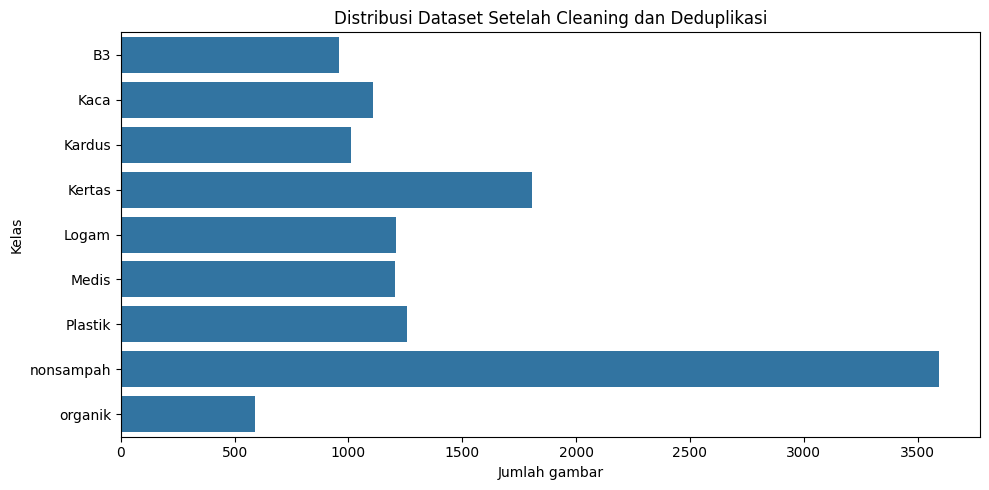

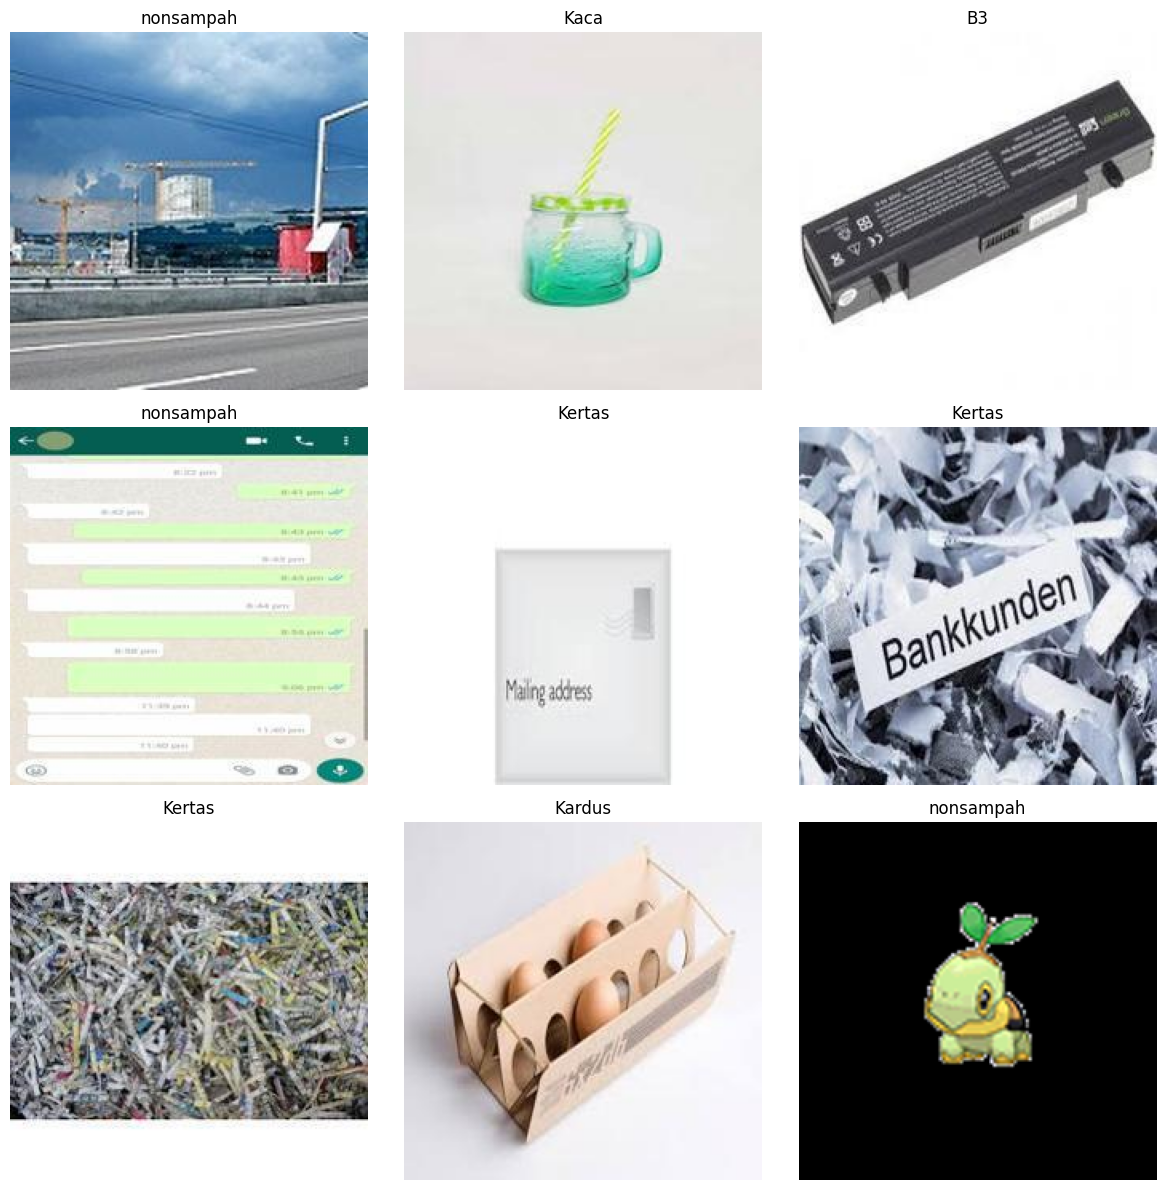

In [12]:
all_images, all_labels = [], []
for cls in sorted(os.listdir(BASE_PATH)):
    class_dir = os.path.join(BASE_PATH, cls)
    if not os.path.isdir(class_dir):
        continue
    for fname in sorted(os.listdir(class_dir)):
        if fname.lower().endswith(VALID_EXT):
            all_images.append(os.path.join(cls, fname))
            all_labels.append(cls)

if not all_images:
    raise RuntimeError("Tidak ada gambar ditemukan. Periksa struktur ZIP dan folder kelas.")

print("Total gambar final:", len(all_images))
print("Jumlah kelas:", len(set(all_labels)))
print("Distribusi:", Counter(all_labels))

plt.figure(figsize=(10, 5))
sns.countplot(y=all_labels, order=sorted(set(all_labels)))
plt.title("Distribusi Dataset Setelah Cleaning dan Deduplikasi")
plt.xlabel("Jumlah gambar")
plt.ylabel("Kelas")
plt.tight_layout()
plt.savefig(os.path.join(DIRS["results"], "class_distribution.png"), dpi=300)
plt.show()

rng = random.Random(SEED)
sample_indices = rng.sample(range(len(all_images)), min(9, len(all_images)))
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for ax, idx in zip(axes.flatten(), sample_indices):
    im = Image.open(os.path.join(BASE_PATH, all_images[idx])).convert("RGB")
    ax.imshow(im)
    ax.set_title(all_labels[idx])
    ax.axis("off")
for ax in axes.flatten()[len(sample_indices):]:
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(DIRS["results"], "sample_images.png"), dpi=300)
plt.show()

CELL 5B — [Reviewer B] Karakteristik dan variasi kondisi citra (resolusi, format, pencahayaan)

,n_sampled,width_min,width_median,width_max,height_min,height_median,height_max,aspect_ratio_median,brightness_mean,brightness_std,contrast_mean,file_kb_median
Class,,,,,,,,,,,,
B3,300,224,224.0,224,224,224.0,224,1.0,186.17,37.61,71.56,6.48
Kaca,300,224,224.0,224,224,224.0,224,1.0,189.86,47.93,47.07,6.49
Kardus,300,224,224.0,224,224,224.0,224,1.0,176.06,34.40,49.25,5.74
Kertas,300,224,224.0,224,224,224.0,224,1.0,188.78,45.14,42.59,7.74
Logam,300,224,224.0,224,224,224.0,224,1.0,178.32,49.60,50.74,7.03
Medis,300,224,224.0,224,224,224.0,224,1.0,164.10,48.17,38.44,5.74
Plastik,300,224,224.0,224,224,224.0,224,1.0,177.85,51.68,43.93,7.85
nonsampah,300,224,224.0,224,224,224.0,224,1.0,104.78,50.57,60.24,8.73
organik,300,224,224.0,224,224,224.0,224,1.0,152.98,20.99,42.25,12.55


Format file : {'JPEG': 2671, 'PNG': 29}
Mode warna  : {'RGB': 2700}
Resolusi (semua sampel): lebar 224-224 px, tinggi 224-224 px
Semua gambar di-resize ke (224, 224) sebelum masuk model.


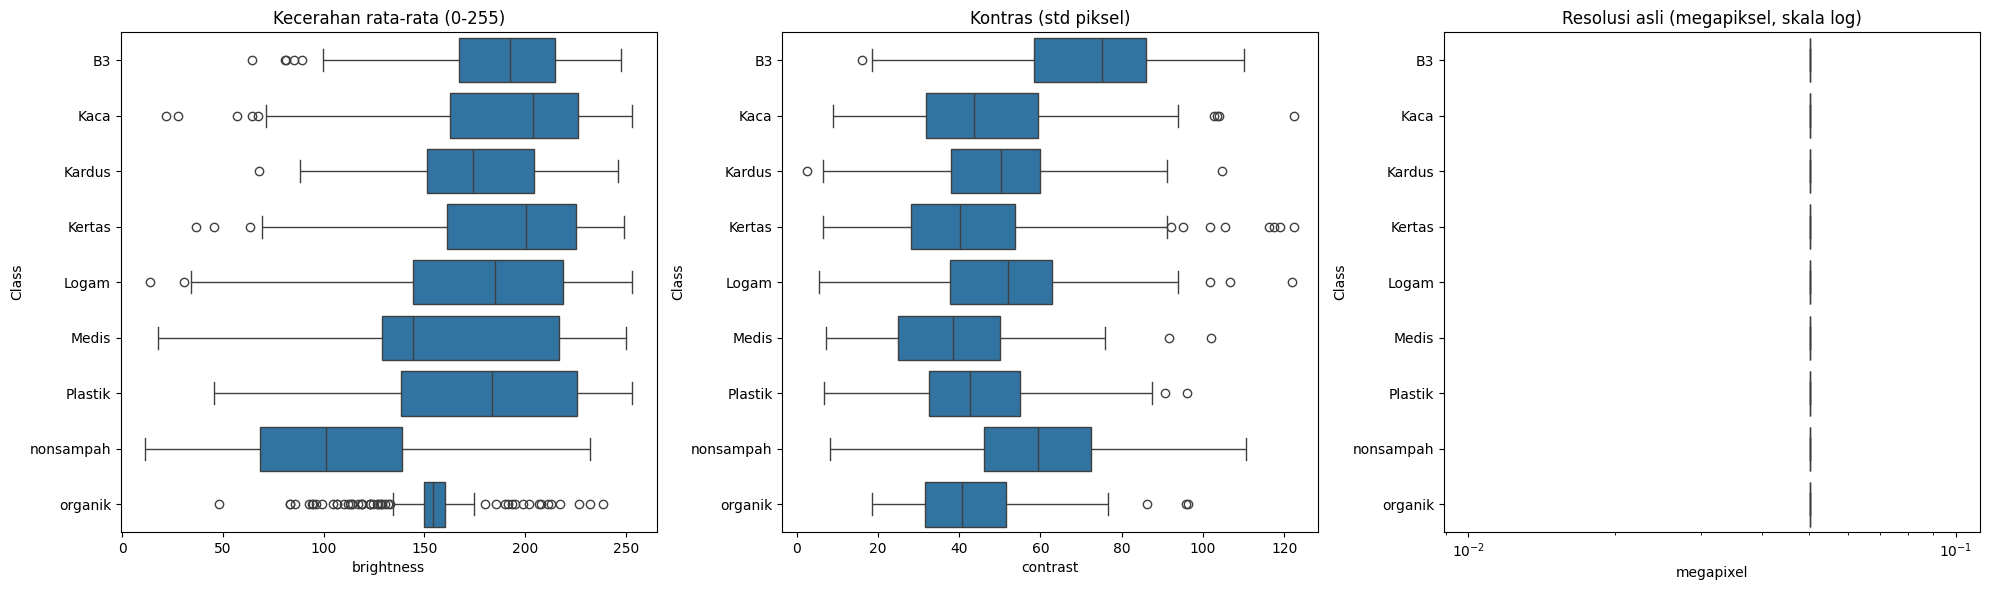

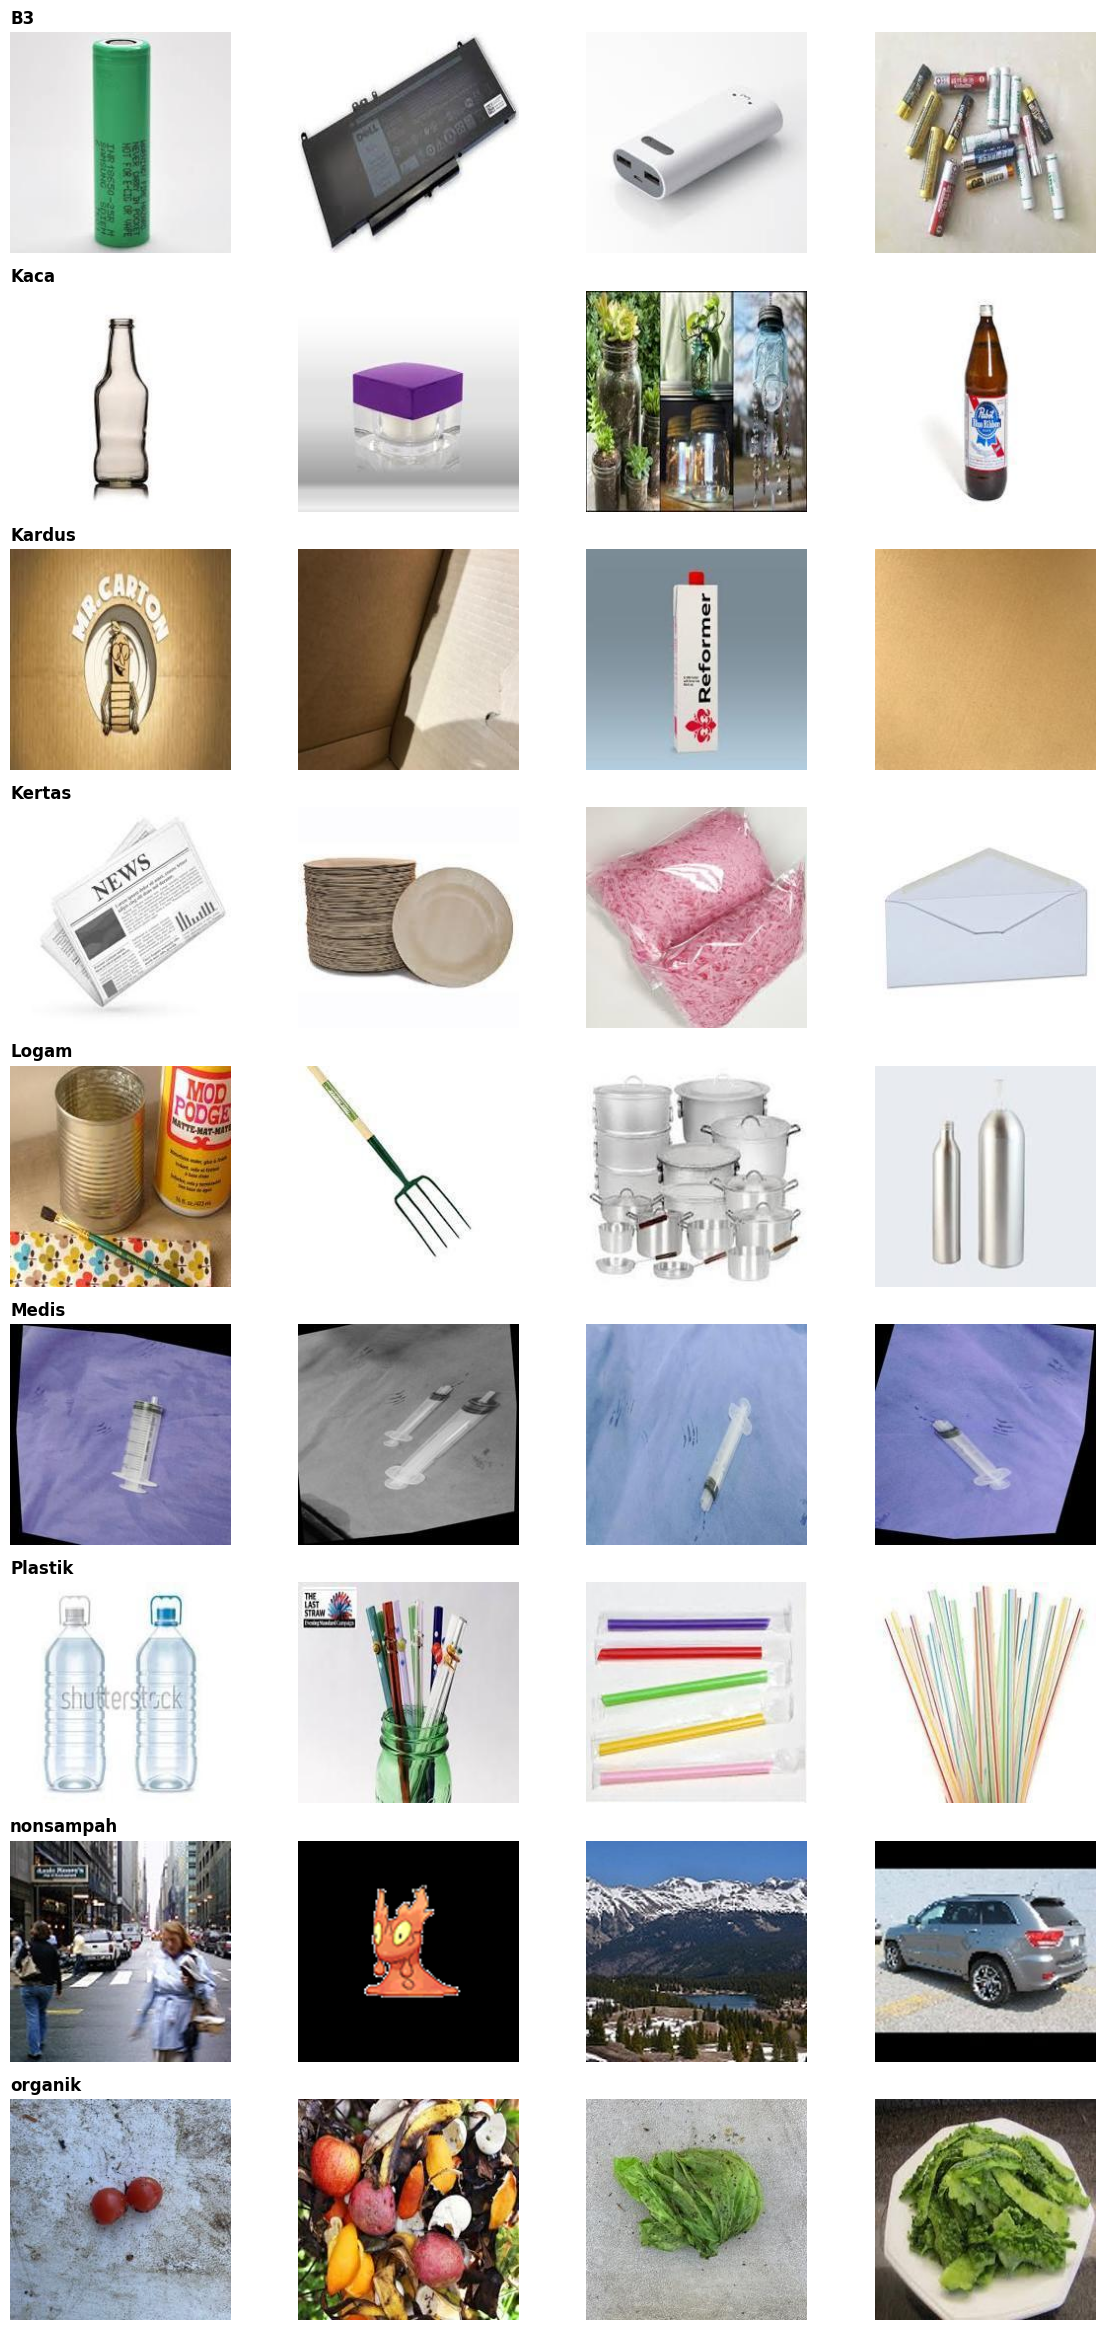

In [13]:
# Statistik citra dihitung dari sampel acak per kelas (seed tetap) agar cepat dan dapat direproduksi.
N_PER_CLASS_STATS = 300
rng_stats = random.Random(SEED)

by_class = {}
for rel, lab in zip(all_images, all_labels):
    by_class.setdefault(lab, []).append(rel)

stat_rows = []
for cls, rels in sorted(by_class.items()):
    chosen = rng_stats.sample(rels, min(N_PER_CLASS_STATS, len(rels)))
    for rel in chosen:
        p = os.path.join(BASE_PATH, rel)
        try:
            with Image.open(p) as im:
                w, h = im.size
                fmt, mode = im.format, im.mode
                g = np.asarray(im.convert("L").resize((64, 64)), dtype=np.float32)
            stat_rows.append({
                "Class": cls, "width": w, "height": h,
                "megapixel": w * h / 1e6, "aspect_ratio": w / h,
                "format": fmt, "mode": mode,
                "brightness": float(g.mean()), "contrast": float(g.std()),
                "file_kb": os.path.getsize(p) / 1024,
            })
        except Exception:
            continue

df_img_stats = pd.DataFrame(stat_rows)
df_img_stats.to_csv(os.path.join(DIRS["results"], "image_characteristics_sampled.csv"), index=False)

summary_img = df_img_stats.groupby("Class").agg(
    n_sampled=("width", "size"),
    width_min=("width", "min"), width_median=("width", "median"), width_max=("width", "max"),
    height_min=("height", "min"), height_median=("height", "median"), height_max=("height", "max"),
    aspect_ratio_median=("aspect_ratio", "median"),
    brightness_mean=("brightness", "mean"), brightness_std=("brightness", "std"),
    contrast_mean=("contrast", "mean"),
    file_kb_median=("file_kb", "median"),
).round(2)
display(summary_img)
summary_img.to_csv(os.path.join(DIRS["results"], "image_characteristics_summary.csv"))

print("Format file :", dict(Counter(df_img_stats["format"])))
print("Mode warna  :", dict(Counter(df_img_stats["mode"])))
print(f"Resolusi (semua sampel): lebar {df_img_stats['width'].min()}-{df_img_stats['width'].max()} px, "
      f"tinggi {df_img_stats['height'].min()}-{df_img_stats['height'].max()} px")
print("Semua gambar di-resize ke", IMAGE_SIZE, "sebelum masuk model.")

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
order = sorted(by_class)
sns.boxplot(data=df_img_stats, y="Class", x="brightness", order=order, ax=axes[0])
axes[0].set_title("Kecerahan rata-rata (0-255)")
sns.boxplot(data=df_img_stats, y="Class", x="contrast", order=order, ax=axes[1])
axes[1].set_title("Kontras (std piksel)")
sns.boxplot(data=df_img_stats, y="Class", x="megapixel", order=order, ax=axes[2])
axes[2].set_xscale("log")
axes[2].set_title("Resolusi asli (megapiksel, skala log)")
plt.tight_layout()
plt.savefig(os.path.join(DIRS["results"], "image_characteristics.png"), dpi=300)
plt.show()

# Contoh visual: 4 gambar acak untuk setiap kelas (menunjukkan variasi latar, sudut, pencahayaan)
SAMPLES_PER_CLASS = 4
fig, axes = plt.subplots(len(order), SAMPLES_PER_CLASS, figsize=(3 * SAMPLES_PER_CLASS, 2.6 * len(order)))
rng_vis = random.Random(SEED + 1)
for r, cls in enumerate(order):
    picks = rng_vis.sample(by_class[cls], min(SAMPLES_PER_CLASS, len(by_class[cls])))
    for c in range(SAMPLES_PER_CLASS):
        ax = axes[r, c]
        ax.axis("off")
        if c < len(picks):
            ax.imshow(Image.open(os.path.join(BASE_PATH, picks[c])).convert("RGB"))
            if c == 0:
                ax.set_title(cls, loc="left", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(DIRS["results"], "sample_images_per_class.png"), dpi=200)
plt.show()


CELL 6 — Stratified split 70:20:10 dan penyimpanan manifest

In [14]:
# Split dibuat sekali dan disimpan. Jika runtime timeout, split yang sudah ada dipakai kembali.
SPLIT_MANIFEST = os.path.join(DIRS["split"], "split_manifest.json")
split_dirs = {s: os.path.join(DIRS["split"], s) for s in ["train", "val", "test"]}

if os.path.exists(SPLIT_MANIFEST) and all(os.path.isdir(p) for p in split_dirs.values()):
    print("Split tersimpan ditemukan. Memuat manifest yang sudah ada.")
    with open(SPLIT_MANIFEST, "r") as f:
        split_manifest = json.load(f)
else:
    train_imgs, temp_imgs, train_labels, temp_labels = train_test_split(
        all_images, all_labels, test_size=0.30, stratify=all_labels, random_state=SEED
    )
    val_imgs, test_imgs, val_labels, test_labels = train_test_split(
        temp_imgs, temp_labels, test_size=1/3, stratify=temp_labels, random_state=SEED
    )

    for split_name, imgs, labels in [
        ("train", train_imgs, train_labels),
        ("val", val_imgs, val_labels),
        ("test", test_imgs, test_labels)
    ]:
        dest_root = split_dirs[split_name]
        if os.path.exists(dest_root):
            shutil.rmtree(dest_root)
        os.makedirs(dest_root, exist_ok=True)
        for rel_path, label in zip(imgs, labels):
            src = os.path.join(BASE_PATH, rel_path)
            dest_class = os.path.join(dest_root, label)
            os.makedirs(dest_class, exist_ok=True)
            shutil.copy2(src, os.path.join(dest_class, os.path.basename(rel_path)))

    split_manifest = {
        "seed": SEED,
        "ratios": {"train": 0.70, "validation": 0.20, "test": 0.10},
        "train": list(zip(train_imgs, train_labels)),
        "val": list(zip(val_imgs, val_labels)),
        "test": list(zip(test_imgs, test_labels))
    }
    # JSON serializable
    for key in ["train", "val", "test"]:
        split_manifest[key] = [{"path": p, "label": y} for p, y in split_manifest[key]]
    with open(SPLIT_MANIFEST, "w") as f:
        json.dump(split_manifest, f, indent=2)

split_counts = {s: sum(class_distribution(p).values()) for s, p in split_dirs.items()}
print("Jumlah gambar per split:", split_counts)
print("Total split:", sum(split_counts.values()))

Split tersimpan ditemukan. Memuat manifest yang sudah ada.
Jumlah gambar per split: {'train': 8917, 'val': 2548, 'test': 1274}
Total split: 12739


CELL 6B — [Reviewer B] Distribusi kelas pada train / validation / test

In [15]:
split_class_counts = {s: class_distribution(p) for s, p in split_dirs.items()}
split_table = pd.DataFrame({
    "Class": sorted(split_class_counts["train"]),
})
for s in ["train", "val", "test"]:
    split_table[s.capitalize()] = split_table["Class"].map(split_class_counts[s]).fillna(0).astype(int)
split_table["Total"] = split_table[["Train", "Val", "Test"]].sum(axis=1)
for s in ["Train", "Val", "Test"]:
    split_table[f"{s} (%)"] = (100 * split_table[s] / split_table[s].sum()).round(2)

total_row = {"Class": "TOTAL"}
for col in ["Train", "Val", "Test", "Total"]:
    total_row[col] = int(split_table[col].sum())
for col in ["Train (%)", "Val (%)", "Test (%)"]:
    total_row[col] = 100.0
split_table = pd.concat([split_table, pd.DataFrame([total_row])], ignore_index=True)
display(split_table)
split_table.to_csv(os.path.join(DIRS["results"], "split_class_distribution.csv"), index=False)

# Pastikan tidak ada file yang sama pada dua split (cek kebocoran berbasis nama file/hash)
def _hash_set(split):
    hs = set()
    for cls in os.listdir(split_dirs[split]):
        d = os.path.join(split_dirs[split], cls)
        if os.path.isdir(d):
            for f in os.listdir(d):
                with open(os.path.join(d, f), "rb") as fh:
                    hs.add(hashlib.md5(fh.read()).hexdigest())
    return hs
h_train, h_val, h_test = _hash_set("train"), _hash_set("val"), _hash_set("test")
print("Overlap exact (MD5) train-val :", len(h_train & h_val))
print("Overlap exact (MD5) train-test:", len(h_train & h_test))
print("Overlap exact (MD5) val-test  :", len(h_val & h_test))


,Class,Train,Val,Test,Total,Train (%),Val (%),Test (%)
0,B3,672,192,96,960,7.54,7.54,7.54
1,Kaca,776,221,111,1108,8.70,8.67,8.71
2,Kardus,709,203,101,1013,7.95,7.97,7.93
3,Kertas,1264,361,181,1806,14.18,14.17,14.21
4,Logam,846,242,121,1209,9.49,9.50,9.50
5,Medis,843,241,120,1204,9.45,9.46,9.42
6,Plastik,879,251,126,1256,9.86,9.85,9.89
7,nonsampah,2516,719,359,3594,28.22,28.22,28.18
8,organik,412,118,59,589,4.62,4.63,4.63
9,TOTAL,8917,2548,1274,12739,100.00,100.00,100.00


Overlap exact (MD5) train-val : 0
Overlap exact (MD5) train-test: 0
Overlap exact (MD5) val-test  : 0


CELL 7 — Augmentasi train-only, generator, dan class weighting

In [16]:
# Parameter augmentasi identik untuk kedua model.
# Validation dan test TIDAK menggunakan augmentasi.
AUGMENTATION_CONFIG = {
    "rotation_range": 30,
    "zoom_range": 0.25,
    "width_shift_range": 0.20,
    "height_shift_range": 0.20,
    "horizontal_flip": True,
    "brightness_range": [0.7, 1.3],
    "shear_range": 0.15,
    "fill_mode": "nearest"
}

def make_generators(preprocess_fn):
    train_datagen = ImageDataGenerator(
        preprocessing_function=preprocess_fn,
        **AUGMENTATION_CONFIG
    )
    eval_datagen = ImageDataGenerator(preprocessing_function=preprocess_fn)

    train_gen = train_datagen.flow_from_directory(
        split_dirs["train"], target_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
        class_mode="categorical", shuffle=True, seed=SEED
    )
    val_gen = eval_datagen.flow_from_directory(
        split_dirs["val"], target_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
        class_mode="categorical", shuffle=False
    )
    test_gen = eval_datagen.flow_from_directory(
        split_dirs["test"], target_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
        class_mode="categorical", shuffle=False
    )
    return train_gen, val_gen, test_gen

mobilenet_train_gen, mobilenet_val_gen, mobilenet_test_gen = make_generators(mobilenet_preprocess)
vgg_train_gen, vgg_val_gen, vgg_test_gen = make_generators(vgg_preprocess)

class_names = list(mobilenet_train_gen.class_indices.keys())
num_classes = mobilenet_train_gen.num_classes
assert class_names == list(vgg_train_gen.class_indices.keys()), "Urutan kelas generator tidak sama."

# Formula balanced class weight: N / (K * n_c)
classes_idx = np.unique(mobilenet_train_gen.classes)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes_idx,
    y=mobilenet_train_gen.classes
)
class_weights = {int(c): float(w) for c, w in zip(classes_idx, weights)}

class_weight_table = pd.DataFrame({
    "class_index": list(class_weights.keys()),
    "class_name": [class_names[i] for i in class_weights.keys()],
    "training_samples": [int(np.sum(mobilenet_train_gen.classes == i)) for i in class_weights.keys()],
    "class_weight": list(class_weights.values())
})
display(class_weight_table)
class_weight_table.to_csv(os.path.join(DIRS["results"], "class_weights.csv"), index=False)

print("Class names:", class_names)
print("Train/val/test:", len(mobilenet_train_gen.classes), len(mobilenet_val_gen.classes), len(mobilenet_test_gen.classes))
print("Class weights:", class_weights)
print("Augmentation hanya aktif pada generator train.")

Found 8917 images belonging to 9 classes.
Found 2548 images belonging to 9 classes.
Found 1274 images belonging to 9 classes.
Found 8917 images belonging to 9 classes.
Found 2548 images belonging to 9 classes.
Found 1274 images belonging to 9 classes.


,class_index,class_name,training_samples,class_weight
0,0,B3,672,1.474372
1,1,Kaca,776,1.276775
2,2,Kardus,709,1.397430
3,3,Kertas,1264,0.783843
4,4,Logam,846,1.171132
5,5,Medis,843,1.175300
6,6,Plastik,879,1.127165
7,7,nonsampah,2516,0.393791
8,8,organik,412,2.404800


Class names: ['B3', 'Kaca', 'Kardus', 'Kertas', 'Logam', 'Medis', 'Plastik', 'nonsampah', 'organik']
Train/val/test: 8917 2548 1274
Class weights: {0: 1.474371693121693, 1: 1.2767754868270331, 2: 1.3974298699263439, 3: 0.7838431786216596, 4: 1.1711321250328341, 5: 1.1752998550151574, 6: 1.1271647073694855, 7: 0.3937908496732026, 8: 2.4048004314994604}
Augmentation hanya aktif pada generator train.


CELL 8 — Callback, log, dan helper penyimpanan

In [17]:
def make_callbacks(model_key, phase, patience):
    ckpt_path = os.path.join(DIRS["models"], f"best_{model_key}_{phase}.keras")
    backup_path = os.path.join(DIRS["checkpoints"], f"{model_key}_{phase}_backup")
    csv_path = os.path.join(DIRS["logs"], f"{model_key}_{phase}_history.csv")
    tb_path = os.path.join(DIRS["logs"], f"{model_key}_{phase}_tensorboard")

    return [
        BackupAndRestore(backup_dir=backup_path, save_freq="epoch"),
        ModelCheckpoint(
            ckpt_path, monitor="val_accuracy", mode="max",
            save_best_only=True, save_weights_only=False, verbose=1
        ),
        EarlyStopping(
            monitor="val_accuracy", mode="max", patience=patience,
            restore_best_weights=True, verbose=1
        ),
        ReduceLROnPlateau(
            monitor="val_loss", factor=0.3, patience=3, min_lr=1e-7, verbose=1
        ),
        CSVLogger(csv_path, append=os.path.exists(csv_path)),
        TensorBoard(log_dir=tb_path, histogram_freq=0)
    ]

print("Callback siap. Backup dan checkpoint disimpan di Google Drive.")

Callback siap. Backup dan checkpoint disimpan di Google Drive.


CELL 9 — Model builder dan hyperparameter tuning MobileNetV2

In [18]:
def compile_model(model, learning_rate):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

def build_mobilenet_model(hp):
    inputs = layers.Input(shape=(224, 224, 3))
    base = MobileNetV2(
        input_shape=(224, 224, 3), include_top=False, weights="imagenet"
    )
    base.trainable = False
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(hp.Float("dropout", 0.3, 0.6, step=0.1))(x)
    outputs = layers.Dense(num_classes, activation="softmax", dtype="float32")(x)
    model = models.Model(inputs, outputs, name="MobileNetV2_transfer")
    return compile_model(model, hp.Float("lr", 1e-5, 1e-3, sampling="log"))

mobilenet_tuner = kt.RandomSearch(
    hypermodel=build_mobilenet_model,
    objective="val_accuracy",
    max_trials=TUNER_TRIALS,
    executions_per_trial=1,
    seed=SEED,
    directory=DIRS["tuner"],
    project_name="mobilenetv2_tuning",
    overwrite=False
)

mobilenet_tuner.search(
    mobilenet_train_gen,
    validation_data=mobilenet_val_gen,
    epochs=TUNER_EPOCHS,
    steps_per_epoch=min(TUNER_STEPS, len(mobilenet_train_gen)),
    validation_steps=TUNER_VALIDATION_STEPS,
    class_weight=class_weights,
    callbacks=[EarlyStopping(monitor="val_accuracy", patience=TUNER_PATIENCE, restore_best_weights=True)],
    verbose=1
)
best_hps_mobilenet = mobilenet_tuner.get_best_hyperparameters(1)[0]
print("Best MobileNetV2:", best_hps_mobilenet.values)
with open(os.path.join(DIRS["results"], "best_hps_mobilenet.json"), "w") as f:
    json.dump(best_hps_mobilenet.values, f, indent=2)

Reloading Tuner from /content/drive/MyDrive/hasil_model_revisi2a/tuner_results/mobilenetv2_tuning/tuner0.json
Best MobileNetV2: {'dropout': 0.5, 'lr': 0.0001715074355925934}


CELL 10 — Hyperparameter tuning VGG16

In [19]:
def build_vgg16_model(hp):
    inputs = layers.Input(shape=(224, 224, 3))
    base = VGG16(input_shape=(224, 224, 3), include_top=False, weights="imagenet")
    base.trainable = False
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(
        hp.Int("dense_units", min_value=256, max_value=512, step=128),
        activation="relu"
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(hp.Float("dropout", 0.3, 0.6, step=0.1))(x)
    outputs = layers.Dense(num_classes, activation="softmax", dtype="float32")(x)
    model = models.Model(inputs, outputs, name="VGG16_transfer")
    return compile_model(model, hp.Float("lr", 1e-5, 1e-3, sampling="log"))

vgg_tuner = kt.RandomSearch(
    hypermodel=build_vgg16_model,
    objective="val_accuracy",
    max_trials=TUNER_TRIALS,
    executions_per_trial=1,
    seed=SEED,
    directory=DIRS["tuner"],
    project_name="vgg16_tuning",
    overwrite=False
)

vgg_tuner.search(
    vgg_train_gen,
    validation_data=vgg_val_gen,
    epochs=TUNER_EPOCHS,
    steps_per_epoch=min(TUNER_STEPS, len(vgg_train_gen)),
    validation_steps=TUNER_VALIDATION_STEPS,
    class_weight=class_weights,
    callbacks=[EarlyStopping(monitor="val_accuracy", patience=TUNER_PATIENCE, restore_best_weights=True)],
    verbose=1
)
best_hps_vgg = vgg_tuner.get_best_hyperparameters(1)[0]
print("Best VGG16:", best_hps_vgg.values)
with open(os.path.join(DIRS["results"], "best_hps_vgg16.json"), "w") as f:
    json.dump(best_hps_vgg.values, f, indent=2)

Reloading Tuner from /content/drive/MyDrive/hasil_model_revisi2a/tuner_results/vgg16_tuning/tuner0.json
Best VGG16: {'dense_units': 512, 'dropout': 0.3, 'lr': 0.0008547485565344062}


CELL 11 — Bangun arsitektur final dan simpan konfigurasi

In [61]:
mobilenet_model = mobilenet_tuner.hypermodel.build(best_hps_mobilenet)
vgg_model = vgg_tuner.hypermodel.build(best_hps_vgg)

print("MobileNetV2 parameters:", f"{mobilenet_model.count_params():,}")
print("VGG16 parameters:", f"{vgg_model.count_params():,}")

mobilenet_model.summary()
vgg_model.summary()

MobileNetV2 parameters: 2,274,633
VGG16 parameters: 14,984,009


Model: "MobileNetV2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 9)              │        11,529 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,274,633 (8.68 MB)

 Trainable params: 14,089 (55.04 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

Model: "VGG16_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 9)              │         4,617 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,984,009 (57.16 MB)

 Trainable params: 268,297 (1.02 MB)

 Non-trainable params: 14,715,712 (56.14 MB)

CELL 12 — Phase 1 training MobileNetV2 (base frozen)

In [62]:
phase1_done = os.path.join(DIRS["checkpoints"], "mobilenetv2_phase1_DONE")
phase1_best = os.path.join(DIRS["models"], "best_mobilenetv2_phase1.keras")

if os.path.exists(phase1_done) and os.path.exists(phase1_best):
    print("MobileNetV2 Phase 1 sudah selesai. Memuat checkpoint terbaik.")
    mobilenet_model = tf.keras.models.load_model(phase1_best)
else:
    history_mobilenet_p1 = mobilenet_model.fit(
        mobilenet_train_gen,
        validation_data=mobilenet_val_gen,
        epochs=PHASE1_EPOCHS,
        class_weight=class_weights,
        callbacks=make_callbacks("mobilenetv2", "phase1", EARLY_STOP_PATIENCE_P1),
        verbose=1
    )
    if os.path.exists(phase1_best):
        mobilenet_model = tf.keras.models.load_model(phase1_best)
        with open(phase1_done, "w") as f:
            f.write("completed")
print("MobileNetV2 Phase 1 selesai/siap.")

Epoch 1/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 234ms/step - accuracy: 0.2252 - loss: 2.7760
Epoch 1: val_accuracy improved from None to 0.72567, saving model to /content/drive/MyDrive/hasil_model_revisi2a/models/best_mobilenetv2_phase1.keras

Epoch 1: finished saving model to /content/drive/MyDrive/hasil_model_revisi2a/models/best_mobilenetv2_phase1.keras
558/558 ━━━━━━━━━━━━━━━━━━━━ 153s 261ms/step - accuracy: 0.3574 - loss: 2.1063 - val_accuracy: 0.7257 - val_loss: 0.8757 - learning_rate: 1.7151e-04
Epoch 2/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 237ms/step - accuracy: 0.6025 - loss: 1.1738
Epoch 2: val_accuracy improved from 0.72567 to 0.82535, saving model to /content/drive/MyDrive/hasil_model_revisi2a/models/best_mobilenetv2_phase1.keras

Epoch 2: finished saving model to /content/drive/MyDrive/hasil_model_revisi2a/models/best_mobilenetv2_phase1.keras
558/558 ━━━━━━━━━━━━━━━━━━━━ 141s 253ms/step - accuracy: 0.6254 - loss: 1.1116 - val_accuracy: 0.8254 - val_loss: 0.5760 - learning_rate: 1.

CELL 13 — Phase 1 training VGG16 (base frozen)

In [63]:
phase1_done_v = os.path.join(DIRS["checkpoints"], "vgg16_phase1_DONE")
phase1_best_v = os.path.join(DIRS["models"], "best_vgg16_phase1.keras")

if os.path.exists(phase1_done_v) and os.path.exists(phase1_best_v):
    print("VGG16 Phase 1 sudah selesai. Memuat checkpoint terbaik.")
    vgg_model = tf.keras.models.load_model(phase1_best_v)
else:
    history_vgg_p1 = vgg_model.fit(
        vgg_train_gen,
        validation_data=vgg_val_gen,
        epochs=PHASE1_EPOCHS,
        class_weight=class_weights,
        callbacks=make_callbacks("vgg16", "phase1", EARLY_STOP_PATIENCE_P1),
        verbose=1
    )
    if os.path.exists(phase1_best_v):
        vgg_model = tf.keras.models.load_model(phase1_best_v)
        with open(phase1_done_v, "w") as f:
            f.write("completed")
print("VGG16 Phase 1 selesai/siap.")

Epoch 1/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 241ms/step - accuracy: 0.6579 - loss: 1.1092
Epoch 1: val_accuracy improved from None to 0.87873, saving model to /content/drive/MyDrive/hasil_model_revisi2a/models/best_vgg16_phase1.keras

Epoch 1: finished saving model to /content/drive/MyDrive/hasil_model_revisi2a/models/best_vgg16_phase1.keras
558/558 ━━━━━━━━━━━━━━━━━━━━ 153s 268ms/step - accuracy: 0.7467 - loss: 0.8038 - val_accuracy: 0.8787 - val_loss: 0.4583 - learning_rate: 8.5475e-04
Epoch 2/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 244ms/step - accuracy: 0.8292 - loss: 0.5351
Epoch 2: val_accuracy improved from 0.87873 to 0.88776, saving model to /content/drive/MyDrive/hasil_model_revisi2a/models/best_vgg16_phase1.keras

Epoch 2: finished saving model to /content/drive/MyDrive/hasil_model_revisi2a/models/best_vgg16_phase1.keras
558/558 ━━━━━━━━━━━━━━━━━━━━ 150s 270ms/step - accuracy: 0.8308 - loss: 0.5348 - val_accuracy: 0.8878 - val_loss: 0.3989 - learning_rate: 8.5475e-04
Epoch 3/15
558/

CELL 14 — Fine-tuning MobileNetV2 (45 layer terakhir pada base model)

In [64]:
phase2_done_m = os.path.join(DIRS["checkpoints"], "mobilenetv2_phase2_DONE")
best_m_path = os.path.join(DIRS["models"], "best_mobilenetv2_phase2.keras")

if os.path.exists(phase2_done_m) and os.path.exists(best_m_path):
    print("MobileNetV2 Phase 2 sudah selesai. Memuat checkpoint terbaik.")
    mobilenet_model = tf.keras.models.load_model(best_m_path)
else:
    # Identifikasi nested base model secara eksplisit.
    base_mobilenet = next(
        layer for layer in mobilenet_model.layers
        if isinstance(layer, tf.keras.Model) and "mobilenet" in layer.name.lower()
    )
    base_mobilenet.trainable = True

    for layer in base_mobilenet.layers:
        layer.trainable = False
    for layer in base_mobilenet.layers[-45:]:
        if not isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = True

    # Head classifier tetap trainable.
    for layer in mobilenet_model.layers:
        if layer is not base_mobilenet:
            layer.trainable = True

    mobilenet_model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-5),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    print("Trainable base layers:", sum(l.trainable for l in base_mobilenet.layers))

    history_mobilenet_p2 = mobilenet_model.fit(
        mobilenet_train_gen,
        validation_data=mobilenet_val_gen,
        epochs=PHASE2_EPOCHS,
        class_weight=class_weights,
        callbacks=make_callbacks("mobilenetv2", "phase2", EARLY_STOP_PATIENCE_P2),
        verbose=1
    )

    if os.path.exists(best_m_path):
        mobilenet_model = tf.keras.models.load_model(best_m_path)
        with open(phase2_done_m, "w") as f:
            f.write("completed")

mobilenet_model.save(os.path.join(DIRS["models"], "best_mobilenetv2.keras"))
print("MobileNetV2 fine-tuning selesai/siap.")

Trainable base layers: 30
Epoch 1/20
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 252ms/step - accuracy: 0.8315 - loss: 0.4999
Epoch 1: val_accuracy improved from None to 0.90188, saving model to /content/drive/MyDrive/hasil_model_revisi2a/models/best_mobilenetv2_phase2.keras

Epoch 1: finished saving model to /content/drive/MyDrive/hasil_model_revisi2a/models/best_mobilenetv2_phase2.keras
558/558 ━━━━━━━━━━━━━━━━━━━━ 166s 276ms/step - accuracy: 0.8291 - loss: 0.5128 - val_accuracy: 0.9019 - val_loss: 0.3125 - learning_rate: 1.0000e-05
Epoch 2/20
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 242ms/step - accuracy: 0.8558 - loss: 0.4475
Epoch 2: val_accuracy did not improve from 0.90188
558/558 ━━━━━━━━━━━━━━━━━━━━ 144s 259ms/step - accuracy: 0.8460 - loss: 0.4732 - val_accuracy: 0.8960 - val_loss: 0.3535 - learning_rate: 1.0000e-05
Epoch 3/20
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 237ms/step - accuracy: 0.8580 - loss: 0.4414
Epoch 3: val_accuracy improved from 0.90188 to 0.91013, saving model to /content/drive/MyDrive/

CELL 15 — Fine-tuning VGG16 (Block 5 convolution layers)

In [65]:
phase2_done_v = os.path.join(DIRS["checkpoints"], "vgg16_phase2_DONE")
best_v_path = os.path.join(DIRS["models"], "best_vgg16_phase2.keras")

if os.path.exists(phase2_done_v) and os.path.exists(best_v_path):
    print("VGG16 Phase 2 sudah selesai. Memuat checkpoint terbaik.")
    vgg_model = tf.keras.models.load_model(best_v_path)
else:
    base_vgg = next(
        layer for layer in vgg_model.layers
        if isinstance(layer, tf.keras.Model) and "vgg" in layer.name.lower()
    )
    base_vgg.trainable = True

    for layer in base_vgg.layers:
        layer.trainable = False
    for layer in base_vgg.layers:
        if layer.name.startswith("block5_conv"):
            layer.trainable = True

    for layer in vgg_model.layers:
        if layer is not base_vgg:
            layer.trainable = True

    vgg_model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-5),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    print("Trainable VGG16 base layers:", sum(l.trainable for l in base_vgg.layers))

    history_vgg_p2 = vgg_model.fit(
        vgg_train_gen,
        validation_data=vgg_val_gen,
        epochs=PHASE2_EPOCHS,
        class_weight=class_weights,
        callbacks=make_callbacks("vgg16", "phase2", EARLY_STOP_PATIENCE_P2),
        verbose=1
    )

    if os.path.exists(best_v_path):
        vgg_model = tf.keras.models.load_model(best_v_path)
        with open(phase2_done_v, "w") as f:
            f.write("completed")

vgg_model.save(os.path.join(DIRS["models"], "best_vgg16.keras"))
print("VGG16 fine-tuning selesai/siap.")

Trainable VGG16 base layers: 3
Epoch 1/20
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 257ms/step - accuracy: 0.9120 - loss: 0.2548
Epoch 1: val_accuracy improved from None to 0.92033, saving model to /content/drive/MyDrive/hasil_model_revisi2a/models/best_vgg16_phase2.keras

Epoch 1: finished saving model to /content/drive/MyDrive/hasil_model_revisi2a/models/best_vgg16_phase2.keras
558/558 ━━━━━━━━━━━━━━━━━━━━ 163s 283ms/step - accuracy: 0.9151 - loss: 0.2579 - val_accuracy: 0.9203 - val_loss: 0.2942 - learning_rate: 1.0000e-05
Epoch 2/20
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 248ms/step - accuracy: 0.9151 - loss: 0.2401
Epoch 2: val_accuracy improved from 0.92033 to 0.93014, saving model to /content/drive/MyDrive/hasil_model_revisi2a/models/best_vgg16_phase2.keras

Epoch 2: finished saving model to /content/drive/MyDrive/hasil_model_revisi2a/models/best_vgg16_phase2.keras
558/558 ━━━━━━━━━━━━━━━━━━━━ 153s 274ms/step - accuracy: 0.9177 - loss: 0.2392 - val_accuracy: 0.9301 - val_loss: 0.2786 - learning_r

CELL 16 — Riwayat training dari CSV (tetap tersedia setelah runtime timeout)

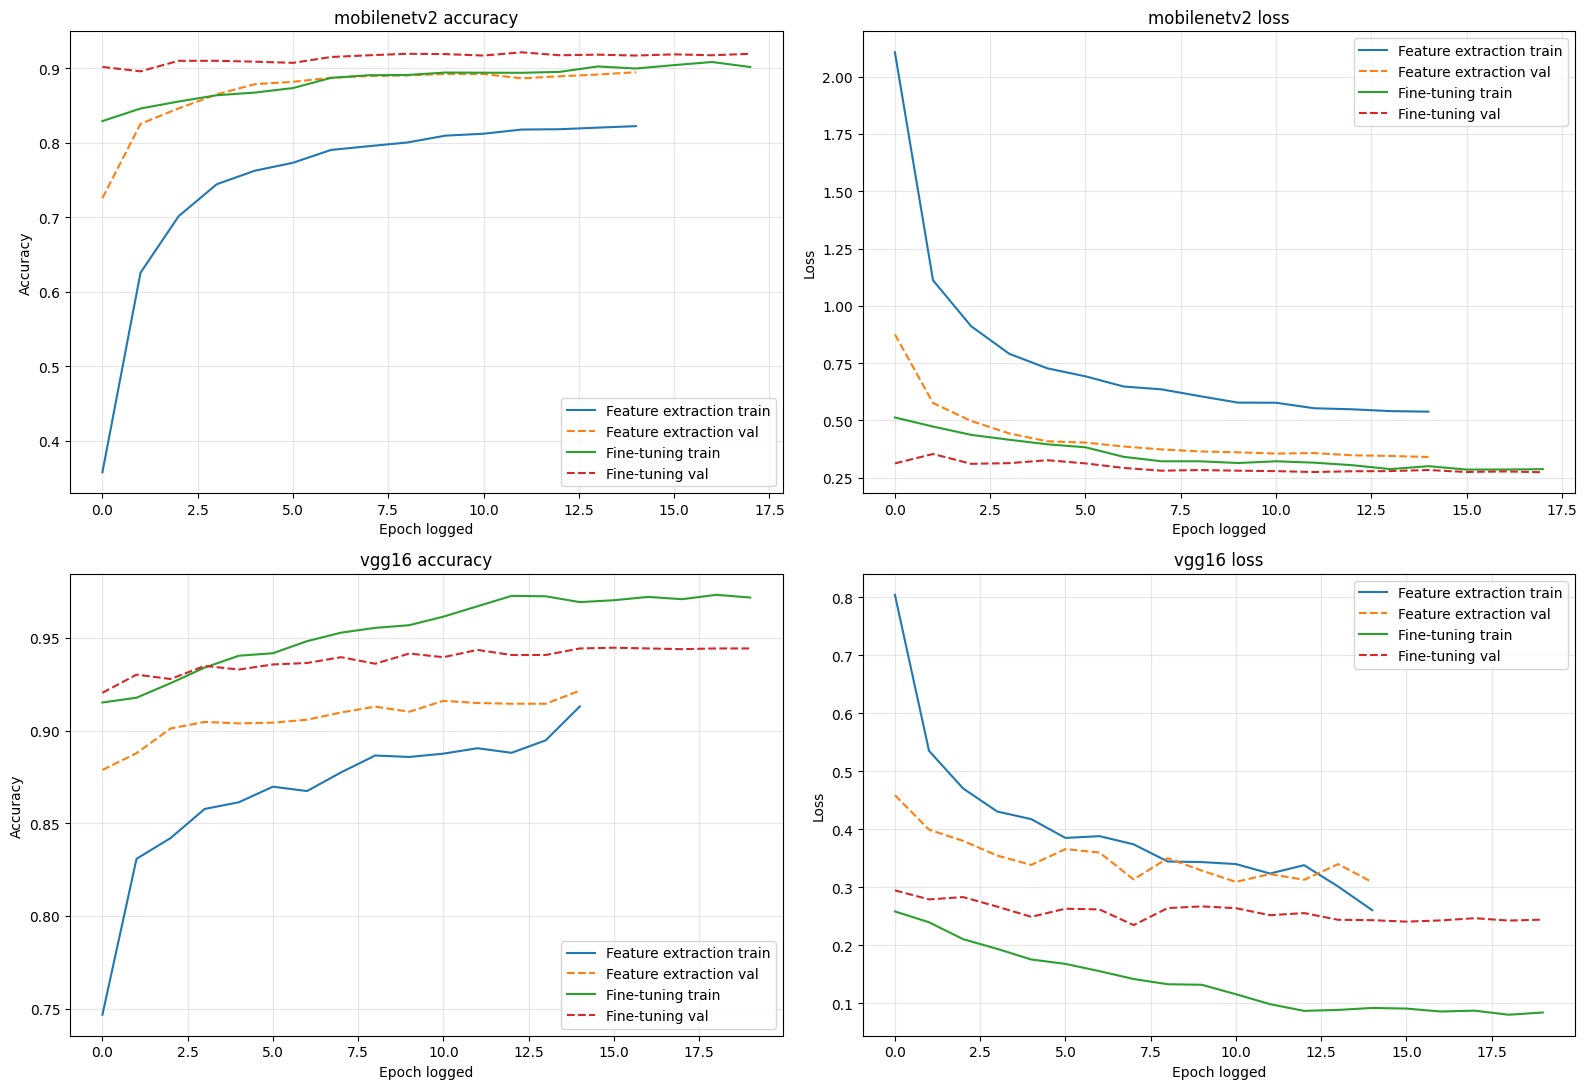

In [66]:
def load_phase_history(model_key, phase):
    path = os.path.join(DIRS["logs"], f"{model_key}_{phase}_history.csv")
    return pd.read_csv(path) if os.path.exists(path) else pd.DataFrame()

histories = {}
for model_key in ["mobilenetv2", "vgg16"]:
    for phase in ["phase1", "phase2"]:
        histories[(model_key, phase)] = load_phase_history(model_key, phase)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for row, model_key in enumerate(["mobilenetv2", "vgg16"]):
    ax_acc, ax_loss = axes[row]
    for phase, label in [("phase1", "Feature extraction"), ("phase2", "Fine-tuning")]:
        df = histories[(model_key, phase)]
        if not df.empty:
            ax_acc.plot(df["accuracy"], label=f"{label} train")
            ax_acc.plot(df["val_accuracy"], linestyle="--", label=f"{label} val")
            ax_loss.plot(df["loss"], label=f"{label} train")
            ax_loss.plot(df["val_loss"], linestyle="--", label=f"{label} val")
    ax_acc.set_title(f"{model_key} accuracy")
    ax_acc.set_xlabel("Epoch logged")
    ax_acc.set_ylabel("Accuracy")
    ax_acc.legend()
    ax_acc.grid(alpha=0.3)
    ax_loss.set_title(f"{model_key} loss")
    ax_loss.set_xlabel("Epoch logged")
    ax_loss.set_ylabel("Loss")
    ax_loss.legend()
    ax_loss.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(DIRS["results"], "training_history_comparison.png"), dpi=300)
plt.show()

CELL 16B — [Reviewer A] Tabel kesetaraan kondisi eksperimen dan parameter augmentasi / class weight

In [67]:
def _trainable_all(model):
    return int(sum(np.prod(w.shape) for w in model.trainable_weights))

def _trainable_head(model):
    total = 0
    for l in model.layers:
        if isinstance(l, tf.keras.Model):   # lewati backbone (nested model)
            continue
        total += int(sum(np.prod(w.shape) for w in l.trainable_weights))
    return total

def _hist_info(model_key):
    out = {}
    for phase in ["phase1", "phase2"]:
        df = load_phase_history(model_key, phase)
        out[phase] = (len(df), float(df["val_accuracy"].max())) if not df.empty else (None, None)
    return out

h_m, h_v = _hist_info("mobilenetv2"), _hist_info("vgg16")

try:
    tp_m1, tp_v1 = _trainable_head(mobilenet_model), _trainable_head(vgg_model)
    tp_m2, tp_v2 = _trainable_all(mobilenet_model), _trainable_all(vgg_model)
except Exception as e:
    print("Trainable params tidak dapat dihitung:", repr(e))
    tp_m1 = tp_v1 = tp_m2 = tp_v2 = None

fairness_rows = [
    ("Dataset & split",            f"Sama: {split_counts}",                                   "Sama"),
    ("Preprocessing",              "Resize 224x224 + mobilenet_v2.preprocess_input (skala [-1,1])",
                                   "Resize 224x224 + vgg16.preprocess_input (mean subtraction, BGR)"),
    ("Augmentasi (train saja)",    "Sama, parameter pada tabel augmentasi",                   "Sama"),
    ("Class weighting",            "Balanced: w_c = N/(K*n_c), sama",                         "Sama"),
    ("Batch size / seed",          f"{BATCH_SIZE} / {SEED}",                                  f"{BATCH_SIZE} / {SEED}"),
    ("Mixed precision",            COMPUTE_POLICY,                                            COMPUTE_POLICY),
    ("Optimizer / loss",           "Adam / categorical cross-entropy",                        "Adam / categorical cross-entropy"),
    ("Metode tuning",              f"RandomSearch, {TUNER_TRIALS} trial, {TUNER_EPOCHS} epoch, {TUNER_STEPS} step/epoch, objective val_accuracy",
                                   f"RandomSearch, {TUNER_TRIALS} trial, {TUNER_EPOCHS} epoch, {TUNER_STEPS} step/epoch, objective val_accuracy"),
    ("Ruang pencarian",            "dropout [0.3-0.6], learning rate [1e-5, 1e-3] (log)",
                                   "dropout [0.3-0.6], learning rate [1e-5, 1e-3] (log), dense units {256,384,512}"),
    ("Hyperparameter terbaik",     str(best_hps_mobilenet.values),                            str(best_hps_vgg.values)),
    ("Head classifier",            "GAP -> BatchNorm -> Dropout -> Dense(softmax)",           "GAP -> Dense(ReLU) -> BatchNorm -> Dropout -> Dense(softmax)"),
    ("Phase 1 (backbone beku)",    f"maks {PHASE1_EPOCHS} epoch, EarlyStopping patience {EARLY_STOP_PATIENCE_P1} (val_accuracy)",
                                   f"maks {PHASE1_EPOCHS} epoch, EarlyStopping patience {EARLY_STOP_PATIENCE_P1} (val_accuracy)"),
    ("Phase 2 (fine-tuning)",      f"45 layer terakhir backbone (BatchNorm tetap beku), Adam 1e-5, maks {PHASE2_EPOCHS} epoch, patience {EARLY_STOP_PATIENCE_P2}",
                                   f"block5_conv1-3, Adam 1e-5, maks {PHASE2_EPOCHS} epoch, patience {EARLY_STOP_PATIENCE_P2}"),
    ("ReduceLROnPlateau",          "monitor val_loss, factor 0.3, patience 3, min_lr 1e-7",   "Sama"),
    ("Epoch yang dijalankan (P1 / P2)", f"{h_m['phase1'][0]} / {h_m['phase2'][0]}",           f"{h_v['phase1'][0]} / {h_v['phase2'][0]}"),
    ("Val accuracy terbaik (P1 / P2)",
        f"{h_m['phase1'][1]:.4f} / {h_m['phase2'][1]:.4f}" if h_m['phase1'][1] is not None and h_m['phase2'][1] is not None else "n/a",
        f"{h_v['phase1'][1]:.4f} / {h_v['phase2'][1]:.4f}" if h_v['phase1'][1] is not None and h_v['phase2'][1] is not None else "n/a"),
    ("Total parameter",            f"{mobilenet_model.count_params():,}",                     f"{vgg_model.count_params():,}"),
    ("Parameter trainable (P1 / P2)",
        f"{tp_m1:,} / {tp_m2:,}" if tp_m1 is not None else "n/a",
        f"{tp_v1:,} / {tp_v2:,}" if tp_v1 is not None else "n/a"),
]
df_fairness = pd.DataFrame(fairness_rows, columns=["Aspek", "MobileNetV2", "VGG16"])
pd.set_option("display.max_colwidth", None)
display(df_fairness)
df_fairness.to_csv(os.path.join(DIRS["results"], "experimental_conditions_both_models.csv"), index=False)

# Tabel parameter augmentasi (Reviewer A: jenis augmentasi + parameter)
aug_desc = {
    "rotation_range": "Rotasi acak (derajat, +/-)",
    "zoom_range": "Zoom acak (fraksi, +/-)",
    "width_shift_range": "Geser horizontal (fraksi lebar)",
    "height_shift_range": "Geser vertikal (fraksi tinggi)",
    "horizontal_flip": "Flip horizontal acak",
    "brightness_range": "Perubahan kecerahan (pengali)",
    "shear_range": "Shear (derajat)",
    "fill_mode": "Pengisian piksel kosong",
}
df_aug = pd.DataFrame({
    "Technique": list(AUGMENTATION_CONFIG.keys()),
    "Description": [aug_desc.get(k, "") for k in AUGMENTATION_CONFIG],
    "Value": [str(v) for v in AUGMENTATION_CONFIG.values()],
    "Applied to": "Training set only",
})
display(df_aug)
df_aug.to_csv(os.path.join(DIRS["results"], "augmentation_parameters.csv"), index=False)

print("Catatan: perbedaan head (VGG16 memakai Dense hidden) dan cakupan layer fine-tuning adalah perbedaan arsitektural "
      "yang disengaja; jumlah trial, epoch tuning, batch size, optimizer, augmentasi, class weight, dan kriteria berhenti dibuat sama.")


,Aspek,MobileNetV2,VGG16
0,Dataset & split,"Sama: {'train': 8917, 'val': 2548, 'test': 1274}",Sama
1,Preprocessing,"Resize 224x224 + mobilenet_v2.preprocess_input (skala [-1,1])","Resize 224x224 + vgg16.preprocess_input (mean subtraction, BGR)"
2,Augmentasi (train saja),"Sama, parameter pada tabel augmentasi",Sama
3,Class weighting,"Balanced: w_c = N/(K*n_c), sama",Sama
4,Batch size / seed,16 / 42,16 / 42
5,Mixed precision,mixed_float16,mixed_float16
6,Optimizer / loss,Adam / categorical cross-entropy,Adam / categorical cross-entropy
7,Metode tuning,"RandomSearch, 10 trial, 3 epoch, 100 step/epoch, objective val_accuracy","RandomSearch, 10 trial, 3 epoch, 100 step/epoch, objective val_accuracy"
8,Ruang pencarian,"dropout [0.3-0.6], learning rate [1e-5, 1e-3] (log)","dropout [0.3-0.6], learning rate [1e-5, 1e-3] (log), dense units {256,384,512}"
9,Hyperparameter terbaik,"{'dropout': 0.5, 'lr': 0.0001715074355925934}","{'dense_units': 512, 'dropout': 0.3, 'lr': 0.0008547485565344062}"


,Technique,Description,Value,Applied to
0,rotation_range,"Rotasi acak (derajat, +/-)",30,Training set only
1,zoom_range,"Zoom acak (fraksi, +/-)",0.25,Training set only
2,width_shift_range,Geser horizontal (fraksi lebar),0.2,Training set only
3,height_shift_range,Geser vertikal (fraksi tinggi),0.2,Training set only
4,horizontal_flip,Flip horizontal acak,True,Training set only
5,brightness_range,Perubahan kecerahan (pengali),"[0.7, 1.3]",Training set only
6,shear_range,Shear (derajat),0.15,Training set only
7,fill_mode,Pengisian piksel kosong,nearest,Training set only


Catatan: perbedaan head (VGG16 memakai Dense hidden) dan cakupan layer fine-tuning adalah perbedaan arsitektural yang disengaja; jumlah trial, epoch tuning, batch size, optimizer, augmentasi, class weight, dan kriteria berhenti dibuat sama.


CELL 17 — Evaluasi test: classification report, macro metrics, dan multiclass AUC OvR

In [68]:
# Pastikan model final tersedia.
mobilenet_model = tf.keras.models.load_model(os.path.join(DIRS["models"], "best_mobilenetv2.keras"))
vgg_model = tf.keras.models.load_model(os.path.join(DIRS["models"], "best_vgg16.keras"))

mobilenet_test_gen.reset()
y_true_m = mobilenet_test_gen.classes.copy()
y_prob_m = mobilenet_model.predict(mobilenet_test_gen, verbose=1)
y_pred_m = np.argmax(y_prob_m, axis=1)

vgg_test_gen.reset()
y_true_v = vgg_test_gen.classes.copy()
y_prob_v = vgg_model.predict(vgg_test_gen, verbose=1)
y_pred_v = np.argmax(y_prob_v, axis=1)

assert np.array_equal(y_true_m, y_true_v), "Urutan label test tidak identik!"

def evaluate_predictions(y_true, y_pred, y_prob, model_name):
    report_dict = classification_report(
        y_true, y_pred, target_names=class_names, output_dict=True, zero_division=0
    )
    report_text = classification_report(
        y_true, y_pred, target_names=class_names, zero_division=0
    )
    auc_ovr_macro = roc_auc_score(
        y_true, y_prob, multi_class="ovr", average="macro"
    )
    metrics_dict = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Precision_weighted": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Recall_weighted": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "F1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "AUC_OvR_macro": auc_ovr_macro,
        "Top3_accuracy": top_k_accuracy_score(y_true, y_prob, k=3, labels=np.arange(num_classes))
    }
    return metrics_dict, report_dict, report_text

metrics_m, report_m_dict, report_m_text = evaluate_predictions(y_true_m, y_pred_m, y_prob_m, "MobileNetV2")
metrics_v, report_v_dict, report_v_text = evaluate_predictions(y_true_v, y_pred_v, y_prob_v, "VGG16")

print("=== MobileNetV2 ===")
print(report_m_text)
print("=== VGG16 ===")
print(report_v_text)

with open(os.path.join(DIRS["results"], "classification_report_mobilenetv2.txt"), "w") as f:
    f.write(report_m_text)
with open(os.path.join(DIRS["results"], "classification_report_vgg16.txt"), "w") as f:
    f.write(report_v_text)

df_overall = pd.DataFrame([metrics_m, metrics_v])
display(df_overall)
df_overall.to_csv(os.path.join(DIRS["results"], "overall_test_metrics.csv"), index=False)

# Per-class metrics untuk pembahasan reviewer.
per_class_rows = []
for cls in class_names:
    per_class_rows.append({
        "Class": cls,
        "Support": int(report_m_dict[cls]["support"]),
        "MobileNet_Precision": report_m_dict[cls]["precision"],
        "MobileNet_Recall": report_m_dict[cls]["recall"],
        "MobileNet_F1": report_m_dict[cls]["f1-score"],
        "VGG16_Precision": report_v_dict[cls]["precision"],
        "VGG16_Recall": report_v_dict[cls]["recall"],
        "VGG16_F1": report_v_dict[cls]["f1-score"]
    })
df_per_class = pd.DataFrame(per_class_rows)
display(df_per_class)
df_per_class.to_csv(os.path.join(DIRS["results"], "per_class_metrics.csv"), index=False)

80/80 ━━━━━━━━━━━━━━━━━━━━ 11s 95ms/step
80/80 ━━━━━━━━━━━━━━━━━━━━ 7s 79ms/step
=== MobileNetV2 ===
              precision    recall  f1-score   support

          B3       0.90      0.92      0.91        96
        Kaca       0.83      0.95      0.88       111
      Kardus       0.89      0.95      0.92       101
      Kertas       0.96      0.85      0.90       181
       Logam       0.85      0.91      0.88       121
       Medis       0.89      0.92      0.91       120
     Plastik       0.87      0.81      0.84       126
   nonsampah       0.98      0.97      0.98       359
     organik       0.98      0.95      0.97        59

    accuracy                           0.92      1274
   macro avg       0.91      0.91      0.91      1274
weighted avg       0.92      0.92      0.92      1274

=== VGG16 ===
              precision    recall  f1-score   support

          B3       0.92      0.95      0.93        96
        Kaca       0.96      0.92      0.94       111
      Kardus     

,Model,Accuracy,Precision_macro,Recall_macro,F1_macro,Precision_weighted,Recall_weighted,F1_weighted,AUC_OvR_macro,Top3_accuracy
0,MobileNetV2,0.918367,0.906721,0.913391,0.908824,0.920883,0.918367,0.918464,0.994829,0.988226
1,VGG16,0.937991,0.928860,0.933278,0.930636,0.939023,0.937991,0.938121,0.996385,0.991366


,Class,Support,MobileNet_Precision,MobileNet_Recall,MobileNet_F1,VGG16_Precision,VGG16_Recall,VGG16_F1
0,B3,96,0.897959,0.916667,0.907216,0.919192,0.947917,0.933333
1,Kaca,111,0.826772,0.945946,0.882353,0.962264,0.918919,0.940092
2,Kardus,101,0.888889,0.950495,0.918660,0.896226,0.940594,0.917874
3,Kertas,181,0.962500,0.850829,0.903226,0.953488,0.906077,0.929178
4,Logam,121,0.852713,0.909091,0.880000,0.871212,0.950413,0.909091
5,Medis,120,0.894309,0.916667,0.905350,0.918033,0.933333,0.925620
6,Plastik,126,0.871795,0.809524,0.839506,0.909836,0.880952,0.895161
7,nonsampah,359,0.983099,0.972145,0.977591,0.980337,0.972145,0.976224
8,organik,59,0.982456,0.949153,0.965517,0.949153,0.949153,0.949153


CELL 17B — [Reviewer A] Detail AUC multikelas (OvR vs OvO, macro vs weighted), AUC per kelas, kurva ROC, log-loss

,Model,Accuracy,AUC_OVR_macro,AUC_OVR_weighted,AUC_OVO_macro,AUC_OVO_weighted,LogLoss
0,MobileNetV2,0.918367,0.994829,0.995179,0.994600,0.994845,0.265633
1,VGG16,0.937991,0.996385,0.996625,0.996216,0.996358,0.235848


,Class,MobileNetV2_AUC_OvR,VGG16_AUC_OvR
0,B3,0.995641,0.997498
1,Kaca,0.995600,0.997204
2,Kardus,0.993138,0.998016
3,Kertas,0.991892,0.994900
4,Logam,0.993413,0.997018
5,Medis,0.995198,0.997769
6,Plastik,0.991925,0.990100
7,nonsampah,0.998380,0.998493
8,organik,0.998270,0.996471


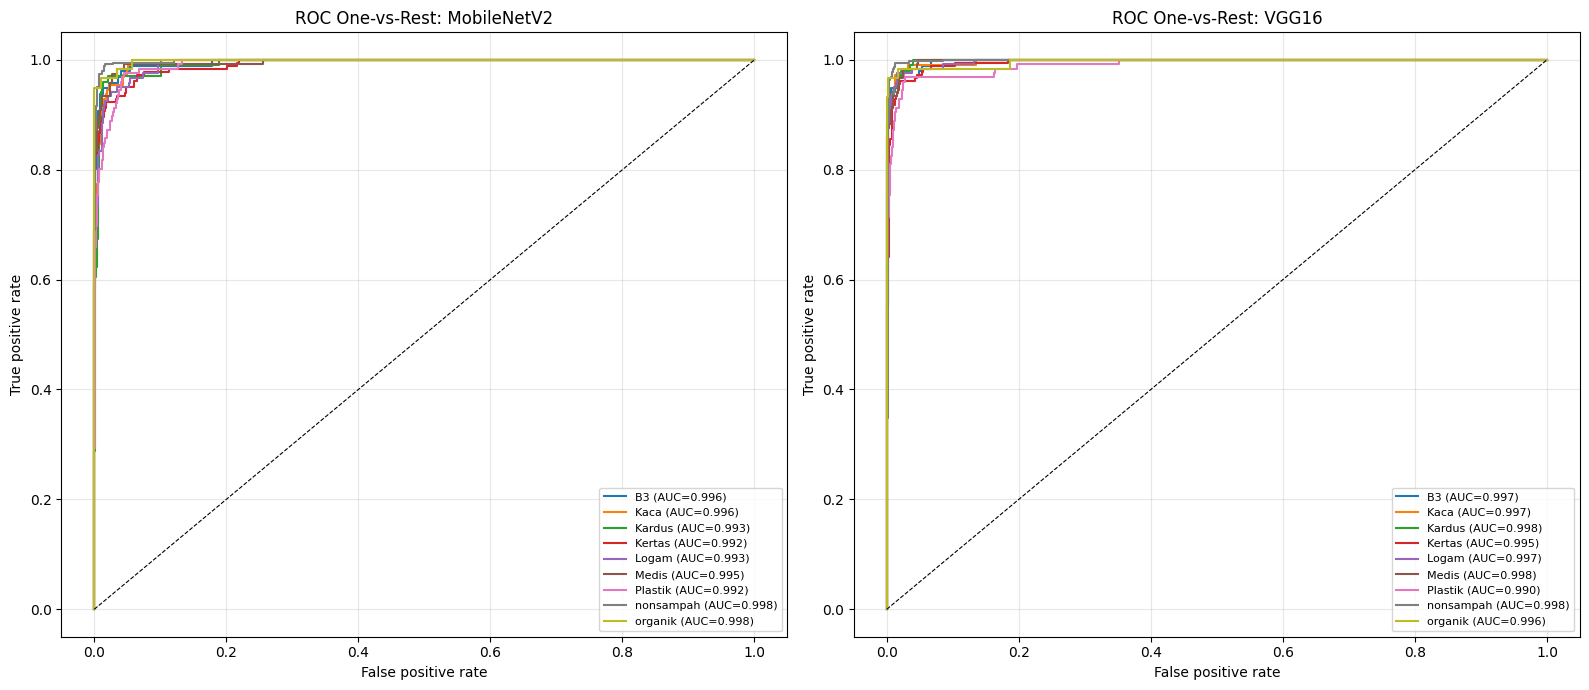

Metode AUC pada paper: One-vs-Rest, rata-rata macro (tiap kelas dihitung terhadap gabungan kelas lain, lalu dirata-rata tanpa bobot). OvO dan weighted dilaporkan sebagai pembanding.
Interpretasi: accuracy menilai keputusan argmax pada satu titik keputusan, sedangkan AUC menilai kualitas pemeringkatan skor probabilitas pada semua threshold. Karena itu selisih keduanya bisa berbeda arah, dan log-loss ikut dilaporkan untuk menilai kualitas probabilitas.


In [69]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc as sk_auc, log_loss

def _norm_prob(p):
    p = np.asarray(p, dtype=np.float64)
    return p / p.sum(axis=1, keepdims=True)

def auc_detail(y_true, y_prob, name):
    p = _norm_prob(y_prob)
    labels = np.arange(num_classes)
    row = {"Model": name, "Accuracy": accuracy_score(y_true, p.argmax(axis=1))}
    for method in ("ovr", "ovo"):
        for avg in ("macro", "weighted"):
            row[f"AUC_{method.upper()}_{avg}"] = roc_auc_score(
                y_true, p, multi_class=method, average=avg, labels=labels
            )
    row["LogLoss"] = log_loss(y_true, p, labels=labels)
    return row

def per_class_auc(y_true, y_prob):
    p = _norm_prob(y_prob)
    yb = label_binarize(y_true, classes=np.arange(num_classes))
    return [roc_auc_score(yb[:, i], p[:, i]) for i in range(num_classes)]

df_auc_detail = pd.DataFrame([
    auc_detail(y_true_m, y_prob_m, "MobileNetV2"),
    auc_detail(y_true_v, y_prob_v, "VGG16"),
])
display(df_auc_detail)
df_auc_detail.to_csv(os.path.join(DIRS["results"], "auc_detail.csv"), index=False)

df_auc_class = pd.DataFrame({
    "Class": class_names,
    "MobileNetV2_AUC_OvR": per_class_auc(y_true_m, y_prob_m),
    "VGG16_AUC_OvR": per_class_auc(y_true_v, y_prob_v),
})
display(df_auc_class)
df_auc_class.to_csv(os.path.join(DIRS["results"], "auc_per_class.csv"), index=False)

# Kurva ROC One-vs-Rest per kelas
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (name, yt, yp) in zip(axes, [("MobileNetV2", y_true_m, y_prob_m), ("VGG16", y_true_v, y_prob_v)]):
    p = _norm_prob(yp)
    yb = label_binarize(yt, classes=np.arange(num_classes))
    for i, cls in enumerate(class_names):
        fpr, tpr, _ = roc_curve(yb[:, i], p[:, i])
        ax.plot(fpr, tpr, label=f"{cls} (AUC={sk_auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], "k--", linewidth=0.8)
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.set_title(f"ROC One-vs-Rest: {name}")
    ax.legend(fontsize=8, loc="lower right")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(DIRS["results"], "roc_curves_ovr.png"), dpi=300)
plt.show()

print("Metode AUC pada paper: One-vs-Rest, rata-rata macro (tiap kelas dihitung terhadap gabungan kelas lain, "
      "lalu dirata-rata tanpa bobot). OvO dan weighted dilaporkan sebagai pembanding.")
print("Interpretasi: accuracy menilai keputusan argmax pada satu titik keputusan, sedangkan AUC menilai kualitas "
      "pemeringkatan skor probabilitas pada semua threshold. Karena itu selisih keduanya bisa berbeda arah, dan "
      "log-loss ikut dilaporkan untuk menilai kualitas probabilitas.")


CELL 17C — [Reviewer B] Uji signifikansi selisih kedua model: McNemar dan bootstrap 95% CI

In [70]:
from scipy.stats import binomtest

correct_m = (y_pred_m == y_true_m)
correct_v = (y_pred_v == y_true_v)
b = int(np.sum(correct_v & ~correct_m))    # VGG16 benar, MobileNetV2 salah
c = int(np.sum(~correct_v & correct_m))    # MobileNetV2 benar, VGG16 salah
n_disc = b + c
p_mcnemar = float(binomtest(b, n_disc, 0.5).pvalue) if n_disc > 0 else 1.0

print("Tabel kontingensi prediksi (n =", len(y_true_m), ")")
print(f"  Keduanya benar      : {int(np.sum(correct_m & correct_v))}")
print(f"  Hanya VGG16 benar   : {b}")
print(f"  Hanya MobileNet benar: {c}")
print(f"  Keduanya salah      : {int(np.sum(~correct_m & ~correct_v))}")
print(f"McNemar exact test p-value = {p_mcnemar:.4f}")

# Paired bootstrap: sampel ulang indeks test yang SAMA untuk kedua model
B_BOOT = 2000
rng_boot = np.random.default_rng(SEED)
n_test = len(y_true_m)
acc_m_b, acc_v_b, f1_m_b, f1_v_b = [], [], [], []
for _ in range(B_BOOT):
    idx = rng_boot.integers(0, n_test, n_test)
    yt = y_true_m[idx]
    acc_m_b.append(np.mean(y_pred_m[idx] == yt))
    acc_v_b.append(np.mean(y_pred_v[idx] == yt))
    f1_m_b.append(f1_score(yt, y_pred_m[idx], average="macro", zero_division=0))
    f1_v_b.append(f1_score(yt, y_pred_v[idx], average="macro", zero_division=0))
acc_m_b, acc_v_b, f1_m_b, f1_v_b = map(np.array, (acc_m_b, acc_v_b, f1_m_b, f1_v_b))

def _ci(a):
    return float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5))

stat_rows = [
    {"Quantity": "Accuracy MobileNetV2", "Estimate": accuracy_score(y_true_m, y_pred_m), "CI95_low": _ci(acc_m_b)[0], "CI95_high": _ci(acc_m_b)[1]},
    {"Quantity": "Accuracy VGG16",       "Estimate": accuracy_score(y_true_v, y_pred_v), "CI95_low": _ci(acc_v_b)[0], "CI95_high": _ci(acc_v_b)[1]},
    {"Quantity": "Accuracy diff (VGG16 - MobileNetV2)", "Estimate": accuracy_score(y_true_v, y_pred_v) - accuracy_score(y_true_m, y_pred_m),
     "CI95_low": _ci(acc_v_b - acc_m_b)[0], "CI95_high": _ci(acc_v_b - acc_m_b)[1]},
    {"Quantity": "Macro-F1 MobileNetV2", "Estimate": f1_score(y_true_m, y_pred_m, average="macro"), "CI95_low": _ci(f1_m_b)[0], "CI95_high": _ci(f1_m_b)[1]},
    {"Quantity": "Macro-F1 VGG16",       "Estimate": f1_score(y_true_v, y_pred_v, average="macro"), "CI95_low": _ci(f1_v_b)[0], "CI95_high": _ci(f1_v_b)[1]},
    {"Quantity": "Macro-F1 diff (VGG16 - MobileNetV2)", "Estimate": f1_score(y_true_v, y_pred_v, average="macro") - f1_score(y_true_m, y_pred_m, average="macro"),
     "CI95_low": _ci(f1_v_b - f1_m_b)[0], "CI95_high": _ci(f1_v_b - f1_m_b)[1]},
]
df_stat = pd.DataFrame(stat_rows)
df_stat["McNemar_p"] = [None, None, p_mcnemar, None, None, None]
display(df_stat)
df_stat.to_csv(os.path.join(DIRS["results"], "statistical_comparison.csv"), index=False)

lo, hi = _ci(acc_v_b - acc_m_b)
print("Selisih akurasi", "SIGNIFIKAN" if (lo > 0 or hi < 0) else "TIDAK signifikan",
      f"(95% CI [{lo:.4f}, {hi:.4f}], McNemar p={p_mcnemar:.4f}). Gunakan kalimat ini sebagai dasar pembahasan, bukan hanya selisih angka.")


Tabel kontingensi prediksi (n = 1274 )
  Keduanya benar      : 1143
  Hanya VGG16 benar   : 52
  Hanya MobileNet benar: 27
  Keduanya salah      : 52
McNemar exact test p-value = 0.0066


,Quantity,Estimate,CI95_low,CI95_high,McNemar_p
0,Accuracy MobileNetV2,0.918367,0.903454,0.933281,NaN
1,Accuracy VGG16,0.937991,0.924647,0.950549,NaN
2,Accuracy diff (VGG16 - MobileNetV2),0.019623,0.005495,0.033752,0.006553
3,Macro-F1 MobileNetV2,0.908824,0.891159,0.925458,NaN
4,Macro-F1 VGG16,0.930636,0.914626,0.944740,NaN
5,Macro-F1 diff (VGG16 - MobileNetV2),0.021812,0.005868,0.037813,NaN


Selisih akurasi SIGNIFIKAN (95% CI [0.0055, 0.0338], McNemar p=0.0066). Gunakan kalimat ini sebagai dasar pembahasan, bukan hanya selisih angka.


CELL 18 — Confusion matrix dan analisis kelas

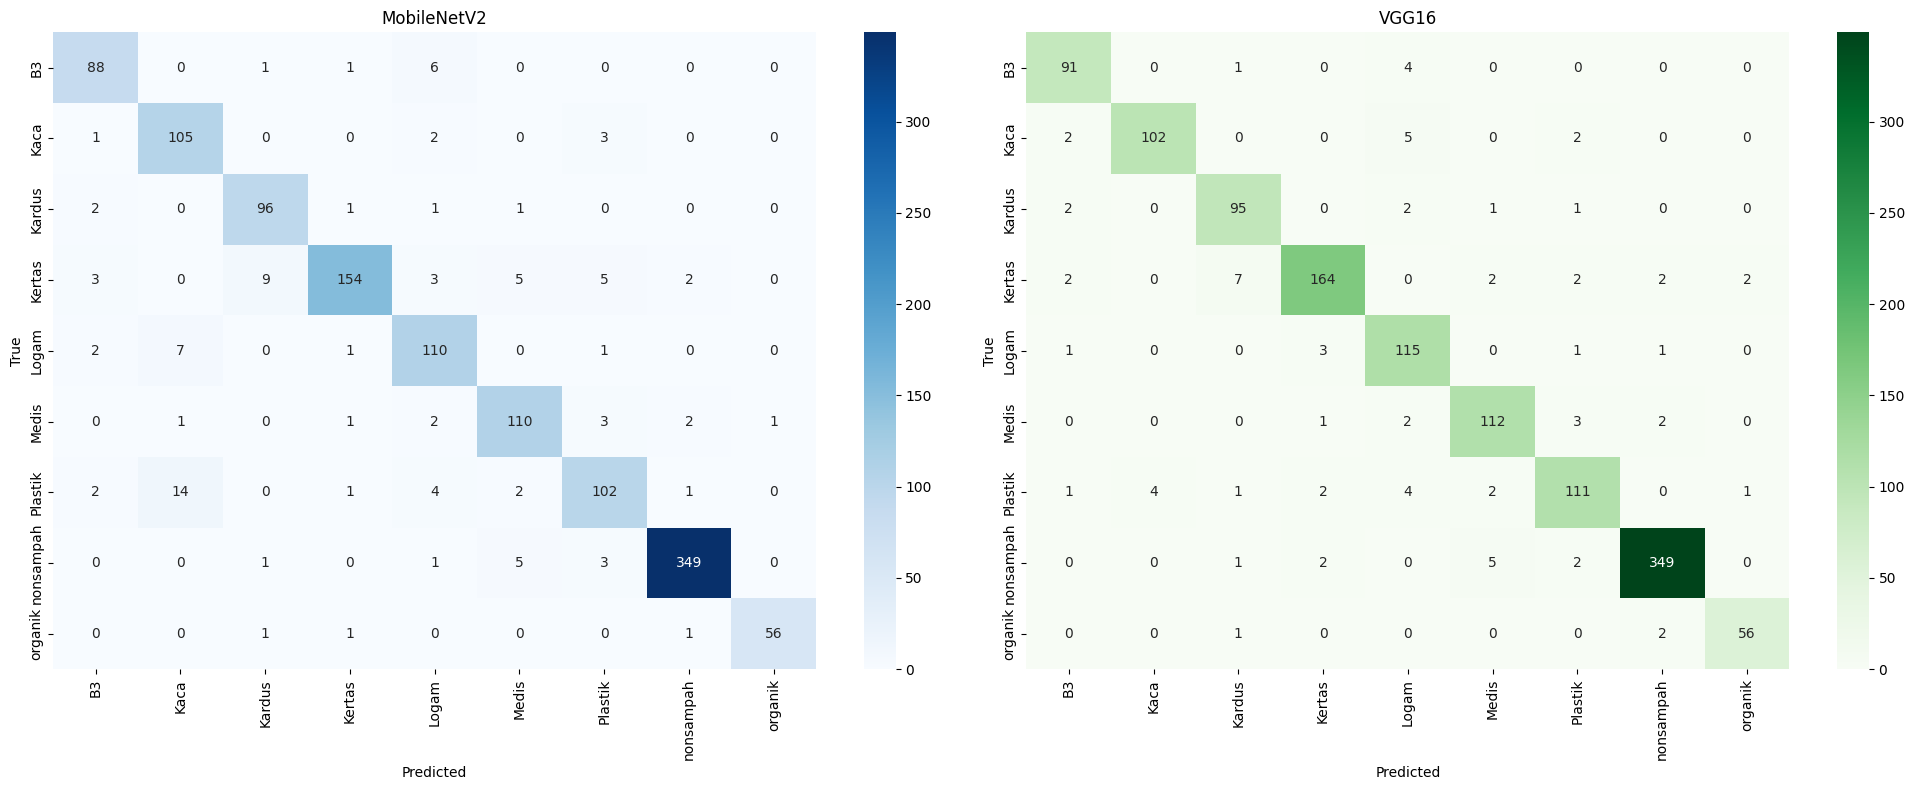

,Class,Support,MobileNetV2_correct,MobileNetV2_recall,VGG16_correct,VGG16_recall
0,B3,96,88,0.916667,91,0.947917
1,Kaca,111,105,0.945946,102,0.918919
2,Kardus,101,96,0.950495,95,0.940594
3,Kertas,181,154,0.850829,164,0.906077
4,Logam,121,110,0.909091,115,0.950413
5,Medis,120,110,0.916667,112,0.933333
6,Plastik,126,102,0.809524,111,0.880952
7,nonsampah,359,349,0.972145,349,0.972145
8,organik,59,56,0.949153,56,0.949153


In [71]:
cm_m = confusion_matrix(y_true_m, y_pred_m)
cm_v = confusion_matrix(y_true_v, y_pred_v)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
sns.heatmap(cm_m, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title("MobileNetV2")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")

sns.heatmap(cm_v, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title("VGG16")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("True")
plt.tight_layout()
plt.savefig(os.path.join(DIRS["results"], "confusion_matrix_comparison.png"), dpi=300)
plt.show()

# Recall per kelas setara dengan proporsi benar pada tiap baris confusion matrix.
class_accuracy_rows = []
for i, cls in enumerate(class_names):
    n = int(np.sum(y_true_m == i))
    class_accuracy_rows.append({
        "Class": cls,
        "Support": n,
        "MobileNetV2_correct": int(cm_m[i, i]),
        "MobileNetV2_recall": float(cm_m[i, i] / n) if n else 0,
        "VGG16_correct": int(cm_v[i, i]),
        "VGG16_recall": float(cm_v[i, i] / n) if n else 0
    })
df_class_recall = pd.DataFrame(class_accuracy_rows)
display(df_class_recall)
df_class_recall.to_csv(os.path.join(DIRS["results"], "per_class_confusion_summary.csv"), index=False)

CELL 18B — [Reviewer B] Analisis kesalahan: confusion matrix ternormalisasi, pasangan kelas tertukar, kelas tersulit

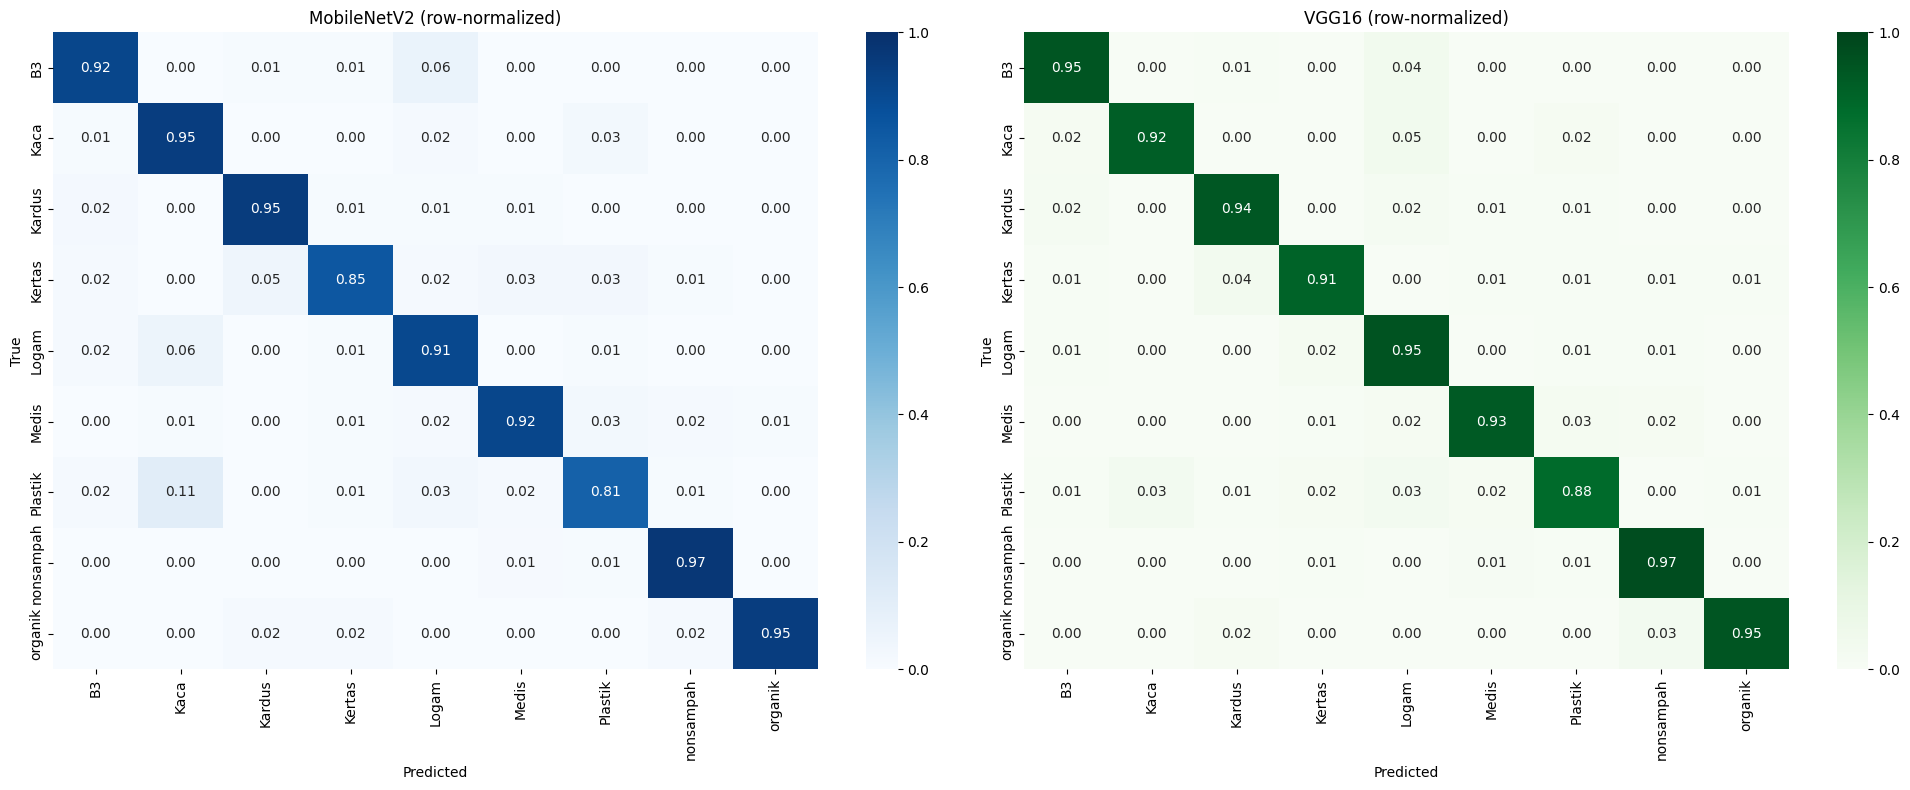

Pasangan kelas yang paling sering tertukar, MobileNetV2:


,True,Predicted,Count,Pct_of_true_class
0,Plastik,Kaca,14,11.11
1,Kertas,Kardus,9,4.97
2,Logam,Kaca,7,5.79
3,B3,Logam,6,6.25
4,Kertas,Plastik,5,2.76
5,Kertas,Medis,5,2.76


Pasangan kelas yang paling sering tertukar, VGG16:


,True,Predicted,Count,Pct_of_true_class
0,Kertas,Kardus,7,3.87
1,Kaca,Logam,5,4.50
2,nonsampah,Medis,5,1.39
3,B3,Logam,4,4.17
4,Plastik,Logam,4,3.17
5,Plastik,Kaca,4,3.17


Kelas diurutkan dari yang tersulit (F1 rata-rata kedua model terendah):


,Class,Support,MobileNet_F1,VGG16_F1,Mean_F1,MobileNet_error_rate,VGG16_error_rate
0,Plastik,126,0.839506,0.895161,0.867334,0.190476,0.119048
1,Logam,121,0.880000,0.909091,0.894545,0.090909,0.049587
2,Kaca,111,0.882353,0.940092,0.911223,0.054054,0.081081
3,Medis,120,0.905350,0.925620,0.915485,0.083333,0.066667
4,Kertas,181,0.903226,0.929178,0.916202,0.149171,0.093923
5,Kardus,101,0.918660,0.917874,0.918267,0.049505,0.059406
6,B3,96,0.907216,0.933333,0.920275,0.083333,0.052083
7,organik,59,0.965517,0.949153,0.957335,0.050847,0.050847
8,nonsampah,359,0.977591,0.976224,0.976907,0.027855,0.027855


Kelas tersulit MobileNetV2: Plastik | VGG16: Plastik


In [72]:
def top_confusions(cm, k=6):
    rows = []
    for i in range(num_classes):
        for j in range(num_classes):
            if i != j and cm[i, j] > 0:
                rows.append({
                    "True": class_names[i], "Predicted": class_names[j],
                    "Count": int(cm[i, j]),
                    "Pct_of_true_class": round(100 * cm[i, j] / cm[i].sum(), 2),
                })
    return pd.DataFrame(rows).sort_values("Count", ascending=False).head(k).reset_index(drop=True)

cm_m_norm = cm_m / cm_m.sum(axis=1, keepdims=True)
cm_v_norm = cm_v / cm_v.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
sns.heatmap(cm_m_norm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title("MobileNetV2 (row-normalized)")
sns.heatmap(cm_v_norm, annot=True, fmt=".2f", cmap="Greens", vmin=0, vmax=1,
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title("VGG16 (row-normalized)")
for ax in axes:
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
plt.tight_layout()
plt.savefig(os.path.join(DIRS["results"], "confusion_matrix_normalized.png"), dpi=300)
plt.show()

tc_m, tc_v = top_confusions(cm_m), top_confusions(cm_v)
print("Pasangan kelas yang paling sering tertukar, MobileNetV2:")
display(tc_m)
print("Pasangan kelas yang paling sering tertukar, VGG16:")
display(tc_v)
tc_m.assign(Model="MobileNetV2").to_csv(os.path.join(DIRS["results"], "top_confusions_mobilenetv2.csv"), index=False)
tc_v.assign(Model="VGG16").to_csv(os.path.join(DIRS["results"], "top_confusions_vgg16.csv"), index=False)

# Kelas tersulit berdasarkan F1 per kelas
hard = df_per_class[["Class", "Support", "MobileNet_F1", "VGG16_F1"]].copy()
hard["Mean_F1"] = hard[["MobileNet_F1", "VGG16_F1"]].mean(axis=1)
hard["MobileNet_error_rate"] = 1 - df_class_recall["MobileNetV2_recall"].values
hard["VGG16_error_rate"] = 1 - df_class_recall["VGG16_recall"].values
hard = hard.sort_values("Mean_F1").reset_index(drop=True)
print("Kelas diurutkan dari yang tersulit (F1 rata-rata kedua model terendah):")
display(hard)
hard.to_csv(os.path.join(DIRS["results"], "hardest_classes.csv"), index=False)
print("Kelas tersulit MobileNetV2:", df_per_class.sort_values("MobileNet_F1").iloc[0]["Class"],
      "| VGG16:", df_per_class.sort_values("VGG16_F1").iloc[0]["Class"])


CELL 19 — Benchmark inference yang terstandar dan ukuran model

In [73]:
# REVISI CELL 19 — Benchmark efisiensi komputasi (Reviewer A)
# Perbaikan: pengukuran sebelumnya memanggil model(...) secara eager. MobileNetV2 punya ratusan layer kecil sehingga
# overhead Python per-layer mendominasi dan latensinya (~180 ms) tampak jauh lebih lambat dari VGG16 (~30 ms),
# padahal itu artefak pengukuran. Sekarang kedua model dijalankan sebagai graph (tf.function) dengan kondisi identik.
import tempfile
from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2_as_graph

BENCH_WARMUP = 30
BENCH_REPEATS = 200
BENCH_ROUNDS = 2          # ronde pertama menstabilkan clock GPU; ronde terakhir yang dilaporkan

def compute_gflops(model):
    try:
        fn = tf.function(lambda x: model(x, training=False))
        concrete = fn.get_concrete_function(tf.TensorSpec([1, 224, 224, 3], tf.float32))
        _, graph_def = convert_variables_to_constants_v2_as_graph(concrete)
        with tf.Graph().as_default() as g:
            tf.graph_util.import_graph_def(graph_def, name="")
            run_meta = tf.compat.v1.RunMetadata()
            opts = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()
            prof = tf.compat.v1.profiler.profile(graph=g, run_meta=run_meta, cmd="op", options=opts)
        return float(prof.total_float_ops) / 1e9
    except Exception as e:
        print("FLOPs tidak dapat dihitung:", repr(e))
        return None

def gpu_peak_delta_mb(infer_fn, x):
    # Selisih memori puncak GPU saat satu kali inferensi (di luar bobot yang sudah termuat).
    try:
        tf.config.experimental.reset_memory_stats("GPU:0")
        base = tf.config.experimental.get_memory_info("GPU:0")["current"]
        _ = infer_fn(x).numpy()
        peak = tf.config.experimental.get_memory_info("GPU:0")["peak"]
        return float(peak - base) / (1024 ** 2)
    except Exception:
        return None

def benchmark_single_image(model, generator, warmup=BENCH_WARMUP, repeats=BENCH_REPEATS, batch_size=1):
    generator.reset()
    batch_x, _ = next(generator)
    sample = tf.constant(batch_x[:batch_size].astype(np.float32))
    infer = tf.function(lambda x: model(x, training=False))   # mode graph, bukan eager

    for _ in range(warmup):
        _ = infer(sample).numpy()

    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        _ = infer(sample).numpy()        # .numpy() memaksa sinkronisasi GPU
        times.append(time.perf_counter() - t0)
    ms = np.asarray(times) * 1000.0
    return {
        "mean_ms": float(ms.mean()),
        "median_ms": float(np.median(ms)),
        "std_ms": float(ms.std()),
        "p95_ms": float(np.percentile(ms, 95)),
        "throughput_img_per_s": float(batch_size / (ms.mean() / 1000.0)),
        "gpu_peak_delta_mb": gpu_peak_delta_mb(infer, sample),
        "warmup": warmup, "repeats": repeats, "batch_size": batch_size,
    }

def weights_file_mb(model):
    # Ukuran bobot saja (tanpa state optimizer), agar adil untuk perbandingan.
    tmp_dir = tempfile.mkdtemp()
    p = os.path.join(tmp_dir, "w.weights.h5")
    model.save_weights(p)
    s = os.path.getsize(p) / (1024 ** 2)
    shutil.rmtree(tmp_dir, ignore_errors=True)
    return s

for _round in range(BENCH_ROUNDS):
    bench_m = benchmark_single_image(mobilenet_model, mobilenet_test_gen, batch_size=1)
    bench_v = benchmark_single_image(vgg_model, vgg_test_gen, batch_size=1)
bench_m16 = benchmark_single_image(mobilenet_model, mobilenet_test_gen, batch_size=BATCH_SIZE)
bench_v16 = benchmark_single_image(vgg_model, vgg_test_gen, batch_size=BATCH_SIZE)

gflops_m, gflops_v = compute_gflops(mobilenet_model), compute_gflops(vgg_model)

model_m_path = os.path.join(DIRS["models"], "best_mobilenetv2.keras")
model_v_path = os.path.join(DIRS["models"], "best_vgg16.keras")
size_m_mb = os.path.getsize(model_m_path) / (1024 ** 2)     # file .keras (termasuk state optimizer)
size_v_mb = os.path.getsize(model_v_path) / (1024 ** 2)
wsize_m_mb, wsize_v_mb = weights_file_mb(mobilenet_model), weights_file_mb(vgg_model)

def _eff_row(name, model, bench, bench16, gflops, keras_mb, weights_mb):
    n = model.count_params()
    return {
        "Model": name,
        "Total_parameters": n,
        "Param_memory_MB_fp32": n * 4 / (1024 ** 2),
        "Weights_file_MB": weights_mb,
        "Keras_file_MB": keras_mb,
        "GFLOPs_per_image": gflops,
        "Inference_mean_ms_per_image": bench["mean_ms"],
        "Inference_median_ms_per_image": bench["median_ms"],
        "Inference_std_ms": bench["std_ms"],
        "Inference_p95_ms": bench["p95_ms"],
        "Throughput_bs16_img_per_s": bench16["throughput_img_per_s"],
        "GPU_peak_delta_MB_bs1": bench["gpu_peak_delta_mb"],
    }

efficiency = pd.DataFrame([
    _eff_row("MobileNetV2", mobilenet_model, bench_m, bench_m16, gflops_m, size_m_mb, wsize_m_mb),
    _eff_row("VGG16", vgg_model, bench_v, bench_v16, gflops_v, size_v_mb, wsize_v_mb),
])
display(efficiency.T)
efficiency.to_csv(os.path.join(DIRS["results"], "model_efficiency.csv"), index=False)

benchmark_info = {
    "device": [d.name for d in tf.config.list_physical_devices()],
    "tensorflow_version": tf.__version__,
    "compute_policy": COMPUTE_POLICY,
    "input_size": IMAGE_SIZE,
    "mode": "tf.function (graph), numpy() sync",
    "warmup": BENCH_WARMUP, "repeats": BENCH_REPEATS, "rounds": BENCH_ROUNDS,
    "mobilenet_bs1": bench_m, "vgg16_bs1": bench_v,
    "mobilenet_bs16": bench_m16, "vgg16_bs16": bench_v16,
    "gflops": {"mobilenet": gflops_m, "vgg16": gflops_v},
    "note": "Keras_file_MB mencakup state optimizer; gunakan Weights_file_MB atau Param_memory_MB_fp32 untuk ukuran model.",
}
with open(os.path.join(DIRS["results"], "inference_benchmark.json"), "w") as f:
    json.dump(benchmark_info, f, indent=2)

print(f"Latensi batch-1 (GPU, graph): MobileNetV2 {bench_m['mean_ms']:.2f} ms vs VGG16 {bench_v['mean_ms']:.2f} ms")
print("Benchmark CPU/edge (TFLite) dijalankan pada Cell 23B setelah model diekspor.")


,0,1
Model,MobileNetV2,VGG16
Total_parameters,2274633,14984009
Param_memory_MB_fp32,8.677036,57.159458
Weights_file_MB,22.36451,113.298218
Keras_file_MB,22.508106,113.319003
GFLOPs_per_image,0.61276,30.713494
Inference_mean_ms_per_image,5.290353,15.024536
Inference_median_ms_per_image,5.240244,15.048265
Inference_std_ms,0.283901,0.199481
Inference_p95_ms,5.642575,15.31763


Latensi batch-1 (GPU, graph): MobileNetV2 5.29 ms vs VGG16 15.02 ms
Benchmark CPU/edge (TFLite) dijalankan pada Cell 23B setelah model diekspor.


CELL 20 — Tabel perbandingan final

,Metric,MobileNetV2,VGG16
0,Accuracy,9.183673e-01,9.379906e-01
1,Precision (macro),9.067213e-01,9.288602e-01
2,Recall (macro),9.133906e-01,9.332781e-01
3,F1-score (macro),9.088244e-01,9.306363e-01
4,AUC (OvR macro),9.948286e-01,9.963853e-01
5,Top-3 accuracy,9.882261e-01,9.913658e-01
6,Total parameters,2.274633e+06,1.498401e+07
7,Model file size (MB),2.250811e+01,1.133190e+02
8,Mean inference latency (ms/image),5.290353e+00,1.502454e+01


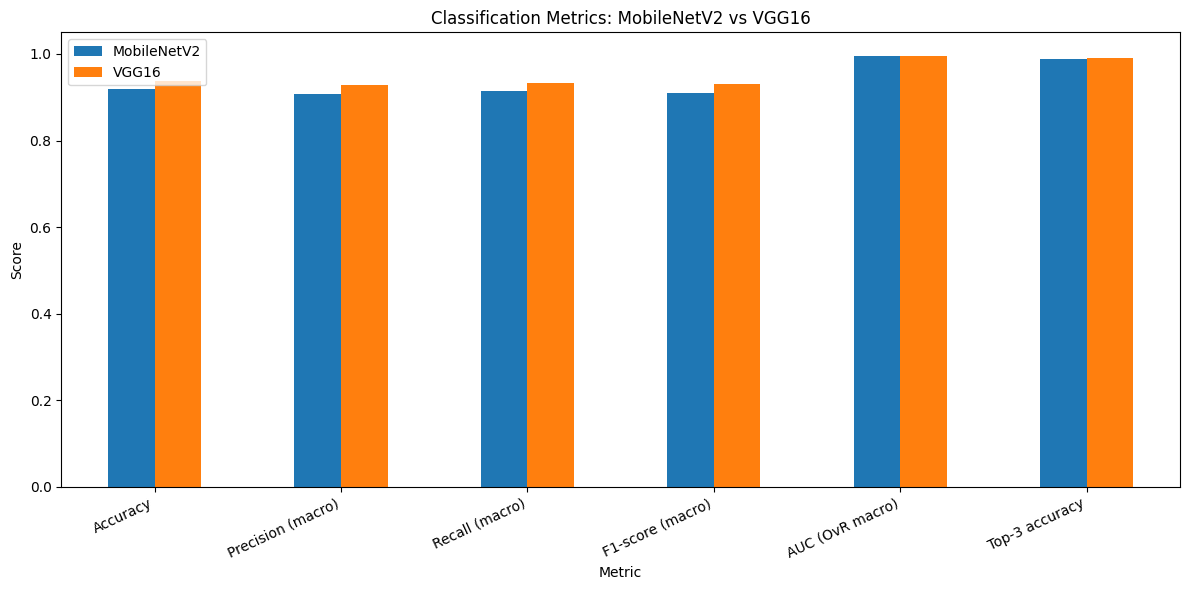

In [74]:
comparison = pd.DataFrame([
    {
        "Metric": "Accuracy",
        "MobileNetV2": metrics_m["Accuracy"],
        "VGG16": metrics_v["Accuracy"]
    },
    {
        "Metric": "Precision (macro)",
        "MobileNetV2": metrics_m["Precision_macro"],
        "VGG16": metrics_v["Precision_macro"]
    },
    {
        "Metric": "Recall (macro)",
        "MobileNetV2": metrics_m["Recall_macro"],
        "VGG16": metrics_v["Recall_macro"]
    },
    {
        "Metric": "F1-score (macro)",
        "MobileNetV2": metrics_m["F1_macro"],
        "VGG16": metrics_v["F1_macro"]
    },
    {
        "Metric": "AUC (OvR macro)",
        "MobileNetV2": metrics_m["AUC_OvR_macro"],
        "VGG16": metrics_v["AUC_OvR_macro"]
    },
    {
        "Metric": "Top-3 accuracy",
        "MobileNetV2": metrics_m["Top3_accuracy"],
        "VGG16": metrics_v["Top3_accuracy"]
    },
    {
        "Metric": "Total parameters",
        "MobileNetV2": mobilenet_model.count_params(),
        "VGG16": vgg_model.count_params()
    },
    {
        "Metric": "Model file size (MB)",
        "MobileNetV2": size_m_mb,
        "VGG16": size_v_mb
    },
    {
        "Metric": "Mean inference latency (ms/image)",
        "MobileNetV2": bench_m["mean_ms"],
        "VGG16": bench_v["mean_ms"]
    }
])
display(comparison)
comparison.to_csv(os.path.join(DIRS["results"], "comparison_table.csv"), index=False)

# Visualisasi metrik klasifikasi
plot_df = comparison[comparison["Metric"].isin([
    "Accuracy", "Precision (macro)", "Recall (macro)",
    "F1-score (macro)", "AUC (OvR macro)", "Top-3 accuracy"
])].set_index("Metric")
ax = plot_df.plot(kind="bar", figsize=(12, 6))
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.set_title("Classification Metrics: MobileNetV2 vs VGG16")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(DIRS["results"], "metrics_comparison.png"), dpi=300)
plt.show()

CELL 21 — Analisis overfitting dari log CSV

In [75]:
for model_key in ["mobilenetv2", "vgg16"]:
    print("\\n", model_key.upper())
    for phase in ["phase1", "phase2"]:
        df = load_phase_history(model_key, phase)
        if df.empty or not {"accuracy", "val_accuracy"}.issubset(df.columns):
            print(phase, ": history belum tersedia")
            continue
        gap = df["accuracy"] - df["val_accuracy"]
        print(
            phase,
            "| mean train-val gap:", round(float(gap.mean()), 4),
            "| max train-val gap:", round(float(gap.max()), 4),
            "| best val accuracy:", round(float(df["val_accuracy"].max()), 4)
        )

\n MOBILENETV2
phase1 | mean train-val gap: -0.1191 | max train-val gap: -0.0688 | best val accuracy: 0.8948
phase2 | mean train-val gap: -0.0308 | max train-val gap: -0.0091 | best val accuracy: 0.9215
\n VGG16
phase1 | mean train-val gap: -0.0401 | max train-val gap: -0.0085 | best val accuracy: 0.9215
phase2 | mean train-val gap: 0.0162 | max train-val gap: 0.0319 | best val accuracy: 0.9447


CELL 22 — Ablation study opsional: dengan/tanpa class weighting dan augmentation

Melanjutkan ablation: 5 eksperimen sudah selesai.
Total eksperimen: 8
Maksimum epoch per eksperimen: 15
SKIP: ('mobilenetv2', 'augmentation_yes_weight_yes', 42)
SKIP: ('mobilenetv2', 'augmentation_yes_weight_no', 42)
SKIP: ('mobilenetv2', 'augmentation_no_weight_yes', 42)
SKIP: ('mobilenetv2', 'augmentation_no_weight_no', 42)
SKIP: ('vgg16', 'augmentation_yes_weight_yes', 42)

MODEL      : vgg16
CONDITION  : augmentation_yes_weight_no
SEED       : 42
Found 8917 images belonging to 9 classes.
Found 2548 images belonging to 9 classes.
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 162s 266ms/step - accuracy: 0.7661 - loss: 0.7472 - val_accuracy: 0.8885 - val_loss: 0.4126 - learning_rate: 8.5475e-04
Epoch 2/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 152s 272ms/step - accuracy: 0.8440 - loss: 0.4863 - val_accuracy: 0.8901 - val_loss: 0.4065 - learning_rate: 8.5475e-04
Epoch 3/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 146s 261ms/step - accuracy: 0.8594 - loss: 0.4339 

,Model,Seed,Augmentation,Class_weighting,Condition,Epochs_run,Best_epoch_val_loss,Best_val_loss,Minority_classes,Val_accuracy,...,Recall_B3,Recall_Kaca,Recall_Kardus,Recall_Kertas,Recall_Logam,Recall_Medis,Recall_Plastik,Recall_nonsampah,Recall_organik,Train_minutes
0,mobilenetv2,42,True,True,augmentation_yes_weight_yes,15,15,0.338426,"organik, B3, Kardus",0.894819,...,0.921875,0.927602,0.891626,0.803324,0.900826,0.858921,0.832669,0.945758,0.957627,33.89
1,mobilenetv2,42,True,False,augmentation_yes_weight_no,15,15,0.316876,"organik, B3, Kardus",0.903454,...,0.921875,0.927602,0.862069,0.839335,0.904959,0.846473,0.828685,0.973574,0.940678,33.56
2,mobilenetv2,42,False,True,augmentation_no_weight_yes,15,15,0.310730,"organik, B3, Kardus",0.899529,...,0.927083,0.923077,0.891626,0.800554,0.880165,0.871369,0.872510,0.949930,0.974576,8.20
3,mobilenetv2,42,False,False,augmentation_no_weight_no,15,15,0.296176,"organik, B3, Kardus",0.906593,...,0.916667,0.914027,0.886700,0.822715,0.880165,0.863071,0.860558,0.979138,0.966102,8.18
4,vgg16,42,True,True,augmentation_yes_weight_yes,15,15,0.285374,"organik, B3, Kardus",0.921900,...,0.927083,0.932127,0.906404,0.864266,0.900826,0.908714,0.880478,0.965229,0.991525,36.57
5,vgg16,42,True,False,augmentation_yes_weight_no,15,15,0.301324,"organik, B3, Kardus",0.917582,...,0.937500,0.914027,0.911330,0.858726,0.892562,0.871369,0.872510,0.973574,0.983051,37.28
6,vgg16,42,False,True,augmentation_no_weight_yes,15,14,0.267776,"organik, B3, Kardus",0.929356,...,0.942708,0.945701,0.931034,0.858726,0.888430,0.929461,0.892430,0.972184,0.991525,13.83
7,vgg16,42,False,False,augmentation_no_weight_no,15,11,0.263986,"organik, B3, Kardus",0.930926,...,0.932292,0.932127,0.891626,0.900277,0.888430,0.887967,0.908367,0.983310,0.991525,13.86


Val_accuracy     Val_macro_precision  \
                                                 mean std                mean   
Model       Augmentation Class_weighting                                        
mobilenetv2 False        False                 0.9066 NaN              0.8960   
                         True                  0.8995 NaN              0.8817   
            True         False                 0.9035 NaN              0.8930   
                         True                  0.8948 NaN              0.8757   
vgg16       False        False                 0.9309 NaN              0.9235   
                         True                  0.9294 NaN              0.9188   
            True         False                 0.9176 NaN              0.9071   
                         True                  0.9219 NaN              0.9087   

                                             Val_macro_recall      \
                                         std             mean std   
Model       Augmentation Class_weighting                            
mobilenetv2 False        False           NaN           0.8988 NaN   
                         True            NaN           0.8990 NaN   
            True         False           NaN           0.8939 NaN   
                         True            NaN           0.8934 NaN   
vgg16       False        False           NaN           0.9240 NaN   
                         True            NaN           0.9280 NaN   
            True         False           NaN           0.9127 NaN   
                         True            NaN           0.9196 NaN   

                                         Val_macro_F1      \
                                                 mean std   
Model       Augmentation Class_weighting                    
mobilenetv2 False        False                 0.8970 NaN   
                         True                  0.8894 NaN   
            True         False                 0.8926 NaN   
                         True                  0.8832 NaN   
vgg16       False        False                 0.9236 NaN   
                         True                  0.9229 NaN   
            True         False                 0.9095 NaN   
                         True                  0.9138 NaN   

                                         Val_balanced_accuracy      \
                                                          mean std   
Model       Augmentation Class_weighting                             
mobilenetv2 False        False                          0.8988 NaN   
                         True                           0.8990 NaN   
            True         False                          0.8939 NaN   
                         True                           0.8934 NaN   
vgg16       False        False                          0.9240 NaN   
                         True                           0.9280 NaN   
            True         False                          0.9127 NaN   
                         True                           0.9196 NaN   

                                         Val_min_class_recall      \
                                                         mean std   
Model       Augmentation Class_weighting                            
mobilenetv2 False        False                         0.8227 NaN   
                         True                          0.8006 NaN   
            True         False                         0.8287 NaN   
                         True                          0.8033 NaN   
vgg16       False        False                         0.8880 NaN   
                         True                          0.8587 NaN   
            True         False                         0.8587 NaN   
                         True                          0.8643 NaN   

                                         Val_minority_recall_mean      \
                                                             mean std   
Model       Augmentation Class_weighting


HASIL ABLATION BERDASARKAN VALIDATION MACRO-F1


,Model,Baseline,Augmentation_only,Class_weighting_only,Both_techniques,Augmentation_main_effect,Class_weighting_main_effect,Interaction_effect
0,mobilenetv2,0.89703,0.89264,0.88937,0.88318,-0.00529,-0.00857,-0.00181
1,vgg16,0.92355,0.90950,0.92294,0.91381,-0.01159,0.00184,0.00492


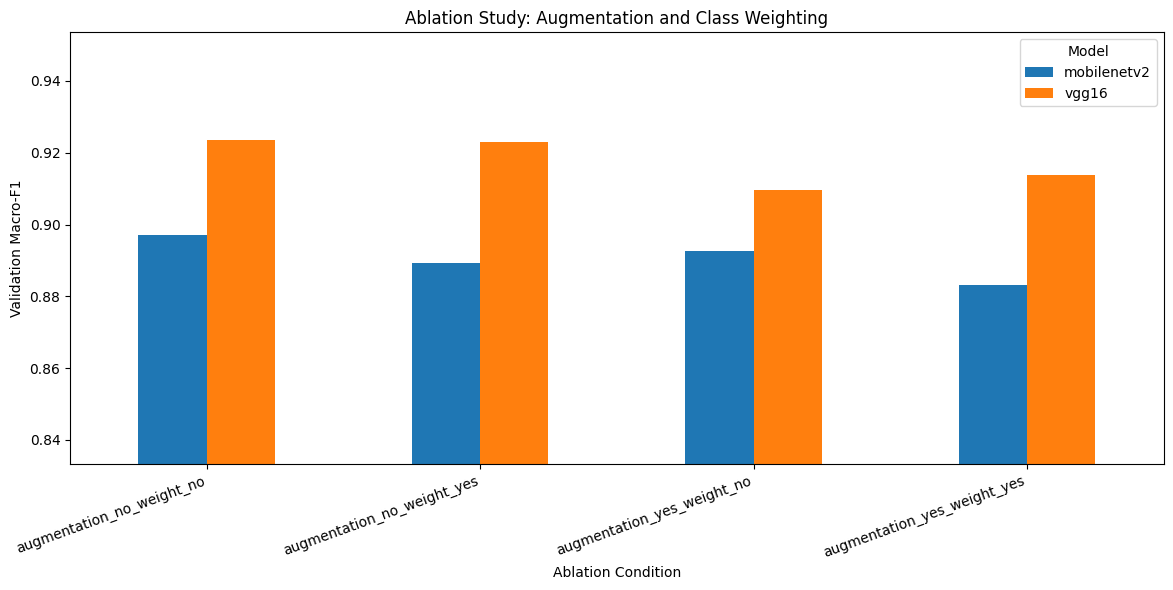

In [20]:

# ============================================================
# CELL 22 — ABLATION STUDY
# Augmentation x Class Weighting
# MobileNetV2 dan VGG16
# Reviewer A — Validation Only
# ============================================================

RUN_ABLATION = True

ABLATION_EPOCHS = PHASE1_EPOCHS
ABLATION_SEEDS = [SEED]  # Gunakan [42, 7, 123] untuk 3 pengulangan

ABLATION_CSV = os.path.join(
    DIRS["results"],
    "ablation_validation_only.csv"
)

# ------------------------------------------------------------
# 1. GENERATOR: TRAIN DAN VALIDATION SAJA
# ------------------------------------------------------------

def make_ablation_generators(preprocess_fn, use_augmentation, seed):

    if use_augmentation:
        train_datagen = ImageDataGenerator(
            preprocessing_function=preprocess_fn,
            **AUGMENTATION_CONFIG
        )
    else:
        train_datagen = ImageDataGenerator(
            preprocessing_function=preprocess_fn
        )

    eval_datagen = ImageDataGenerator(
        preprocessing_function=preprocess_fn
    )

    train_gen = train_datagen.flow_from_directory(
        split_dirs["train"],
        target_size=IMAGE_SIZE,
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        shuffle=True,
        seed=seed
    )

    val_gen = eval_datagen.flow_from_directory(
        split_dirs["val"],
        target_size=IMAGE_SIZE,
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        shuffle=False
    )

    return train_gen, val_gen


# ------------------------------------------------------------
# 2. EVALUASI VALIDATION
# ------------------------------------------------------------

def evaluate_ablation_validation(model, generator, class_labels,
                                 minority_indices):

    generator.reset()

    probabilities = model.predict(
        generator,
        verbose=0
    ).astype(np.float64)

    # Normalisasi probabilitas
    probabilities = probabilities / np.clip(
        probabilities.sum(axis=1, keepdims=True),
        1e-12,
        None
    )

    y_true = generator.classes
    y_pred = np.argmax(probabilities, axis=1)

    labels = np.arange(len(class_labels))

    # Recall setiap kelas
    recalls = recall_score(
        y_true,
        y_pred,
        average=None,
        labels=labels,
        zero_division=0
    )

    # AUC multikelas One-vs-Rest
    try:
        auc_macro = roc_auc_score(
            y_true,
            probabilities,
            multi_class="ovr",
            average="macro",
            labels=labels
        )
    except ValueError:
        auc_macro = np.nan

    metrics = {
        "Val_accuracy": accuracy_score(y_true, y_pred),

        "Val_macro_precision": precision_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),

        "Val_macro_recall": recall_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),

        "Val_macro_F1": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),

        "Val_balanced_accuracy": float(np.mean(recalls)),

        "Val_min_class_recall": float(np.min(recalls)),

        "Val_minority_recall_mean": float(
            np.mean(recalls[minority_indices])
        ),

        "Val_AUC_OvR_macro": auc_macro
    }

    # Simpan recall masing-masing kelas
    for idx, class_name in enumerate(class_labels):
        metrics[f"Recall_{class_name}"] = float(recalls[idx])

    return metrics


# ------------------------------------------------------------
# 3. EMPAT KONDISI EKSPERIMEN
# ------------------------------------------------------------

conditions = [
    (True, True, "augmentation_yes_weight_yes"),
    (True, False, "augmentation_yes_weight_no"),
    (False, True, "augmentation_no_weight_yes"),
    (False, False, "augmentation_no_weight_no")
]


# ------------------------------------------------------------
# 4. LOAD HASIL SEBELUMNYA UNTUK RESUME
# ------------------------------------------------------------

ablation_rows = []
done_keys = set()

if os.path.exists(ABLATION_CSV):

    previous = pd.read_csv(ABLATION_CSV)

    ablation_rows = previous.to_dict("records")

    for row in ablation_rows:

        done_keys.add((
            str(row["Model"]),
            str(row["Condition"]),
            int(row["Seed"])
        ))

    print(
        f"Melanjutkan ablation: "
        f"{len(done_keys)} eksperimen sudah selesai."
    )


# ------------------------------------------------------------
# 5. EKSEKUSI ABLATION
# ------------------------------------------------------------

if RUN_ABLATION:

    total_runs = (
        2 * len(conditions) * len(ABLATION_SEEDS)
    )

    print(f"Total eksperimen: {total_runs}")
    print(f"Maksimum epoch per eksperimen: {ABLATION_EPOCHS}")

    model_configs = [
        (
            "mobilenetv2",
            mobilenet_preprocess,
            mobilenet_tuner.hypermodel,
            best_hps_mobilenet
        ),
        (
            "vgg16",
            vgg_preprocess,
            vgg_tuner.hypermodel,
            best_hps_vgg
        )
    ]

    for seed in ABLATION_SEEDS:

        for model_key, preprocess_fn, builder, hp in model_configs:

            for use_aug, use_weight, condition_name in conditions:

                run_key = (
                    model_key,
                    condition_name,
                    int(seed)
                )

                if run_key in done_keys:
                    print(f"SKIP: {run_key}")
                    continue

                print("\n" + "=" * 60)
                print(f"MODEL      : {model_key}")
                print(f"CONDITION  : {condition_name}")
                print(f"SEED       : {seed}")
                print("=" * 60)

                # Bersihkan memori
                tf.keras.backend.clear_session()
                gc.collect()

                tf.keras.utils.set_random_seed(seed)

                # Generator
                train_ab, val_ab = make_ablation_generators(
                    preprocess_fn,
                    use_aug,
                    seed
                )

                # Pastikan urutan kelas konsisten
                class_labels = [
                    name
                    for name, idx in sorted(
                        train_ab.class_indices.items(),
                        key=lambda item: item[1]
                    )
                ]

                assert train_ab.class_indices == val_ab.class_indices, (
                    "Urutan kelas train dan validation berbeda."
                )

                # Distribusi kelas training
                class_counts = np.bincount(
                    train_ab.classes,
                    minlength=len(class_labels)
                )

                # Identifikasi 25% kelas dengan jumlah sampel terendah
                n_minority = max(
                    1,
                    int(np.ceil(len(class_labels) * 0.25))
                )

                minority_indices = np.argsort(
                    class_counts
                )[:n_minority]

                # Bangun model dengan HP terbaik masing-masing
                model = builder.build(hp)

                # Class weighting hanya diterapkan jika aktif
                cw = class_weights if use_weight else None

                # Training
                start_time = time.time()

                history = model.fit(
                    train_ab,
                    validation_data=val_ab,
                    epochs=ABLATION_EPOCHS,
                    class_weight=cw,
                    callbacks=[
                        EarlyStopping(
                            monitor="val_loss",
                            mode="min",
                            patience=EARLY_STOP_PATIENCE_P1,
                            restore_best_weights=True
                        ),

                        ReduceLROnPlateau(
                            monitor="val_loss",
                            factor=0.3,
                            patience=3,
                            min_lr=1e-7
                        )
                    ],
                    verbose=1
                )

                training_minutes = (
                    time.time() - start_time
                ) / 60

                # Model sudah mengembalikan bobot terbaik
                # berdasarkan validation loss
                val_metrics = evaluate_ablation_validation(
                    model,
                    val_ab,
                    class_labels,
                    minority_indices
                )

                # Epoch terbaik
                best_epoch = (
                    int(np.argmin(history.history["val_loss"])) + 1
                )

                # Simpan hasil
                row = {
                    "Model": model_key,
                    "Seed": int(seed),

                    "Augmentation": bool(use_aug),
                    "Class_weighting": bool(use_weight),

                    "Condition": condition_name,

                    "Epochs_run": len(history.history["loss"]),
                    "Best_epoch_val_loss": best_epoch,

                    "Best_val_loss": float(
                        min(history.history["val_loss"])
                    ),

                    "Minority_classes": ", ".join(
                        class_labels[i]
                        for i in minority_indices
                    ),

                    **val_metrics,

                    "Train_minutes": round(
                        training_minutes, 2
                    )
                }

                ablation_rows.append(row)

                # Simpan langsung setelah satu eksperimen
                pd.DataFrame(ablation_rows).to_csv(
                    ABLATION_CSV,
                    index=False
                )

                done_keys.add(run_key)

                print("\nHASIL VALIDATION:")
                for key, value in row.items():

                    if isinstance(value, (float, np.floating)):
                        print(f"{key}: {value:.4f}")

                    else:
                        print(f"{key}: {value}")

                # Bersihkan objek
                del model, history, train_ab, val_ab

                tf.keras.backend.clear_session()
                gc.collect()

else:
    print(
        "RUN_ABLATION=False: "
        "hanya membaca hasil eksperimen yang tersimpan."
    )


# ------------------------------------------------------------
# 6. RINGKASAN HASIL ABLATION
# ------------------------------------------------------------

if ablation_rows:

    ablation_df = pd.DataFrame(ablation_rows)

    display(ablation_df)

    metric_cols = [
        "Val_accuracy",
        "Val_macro_precision",
        "Val_macro_recall",
        "Val_macro_F1",
        "Val_balanced_accuracy",
        "Val_min_class_recall",
        "Val_minority_recall_mean",
        "Val_AUC_OvR_macro"
    ]

    summary = (
        ablation_df
        .groupby(
            ["Model", "Augmentation", "Class_weighting"]
        )[metric_cols]
        .agg(["mean", "std"])
        .round(4)
    )

    display(summary)

    summary.to_csv(
        os.path.join(
            DIRS["results"],
            "ablation_validation_summary.csv"
        )
    )

    print("\nHASIL ABLATION BERDASARKAN VALIDATION MACRO-F1")

    # --------------------------------------------------------
    # 7. ANALISIS EFEK AUGMENTATION DAN CLASS WEIGHTING
    # --------------------------------------------------------

    effects = []

    for model_name, group in ablation_df.groupby("Model"):

        means = group.groupby(
            ["Augmentation", "Class_weighting"]
        )["Val_macro_F1"].mean()

        required = [
            (False, False),
            (True, False),
            (False, True),
            (True, True)
        ]

        if all(key in means.index for key in required):

            baseline = means.loc[(False, False)]
            aug_only = means.loc[(True, False)]
            weight_only = means.loc[(False, True)]
            both = means.loc[(True, True)]

            effects.append({

                "Model": model_name,

                "Baseline": baseline,

                "Augmentation_only": aug_only,

                "Class_weighting_only": weight_only,

                "Both_techniques": both,

                "Augmentation_main_effect":
                    ((aug_only + both) / 2)
                    - ((baseline + weight_only) / 2),

                "Class_weighting_main_effect":
                    ((weight_only + both) / 2)
                    - ((baseline + aug_only) / 2),

                "Interaction_effect":
                    both - aug_only - weight_only + baseline
            })

        else:
            print(
                f"{model_name}: "
                "belum memiliki empat kombinasi eksperimen."
            )

    if effects:

        effects_df = pd.DataFrame(effects)

        display(effects_df.round(5))

        effects_df.to_csv(
            os.path.join(
                DIRS["results"],
                "ablation_validation_effects.csv"
            ),
            index=False
        )

    # --------------------------------------------------------
    # 8. VISUALISASI VALIDATION MACRO-F1
    # --------------------------------------------------------

    pivot = (
        ablation_df
        .groupby(["Model", "Condition"])["Val_macro_F1"]
        .mean()
        .unstack("Model")
    )

    ax = pivot.plot(
        kind="bar",
        figsize=(12, 6)
    )

    ax.set_ylabel("Validation Macro-F1")
    ax.set_xlabel("Ablation Condition")

    ax.set_title(
        "Ablation Study: Augmentation and Class Weighting"
    )

    ax.set_ylim(
        max(0, pivot.min().min() - 0.05),
        min(1.0, pivot.max().max() + 0.03)
    )

    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            DIRS["results"],
            "ablation_validation_macro_f1.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

else:
    print("Belum ada hasil ablation.")


Analisis ablation berbasis validation set
Cell ini membaca hasil ablation yang sudah dihasilkan oleh Cell 22 dan menghitung efek augmentation serta class weighting menggunakan validation macro-F1 sebagai dasar perbandingan. Cell ini tidak melatih ulang model dan tidak menggunakan test set untuk menentukan teknik terbaik.

In [21]:

# ============================================================
# ANALISIS ABLATION BERDASARKAN VALIDATION SET
# Tidak melakukan training ulang
# Tidak menggunakan test set
# ============================================================

_ablation_csv_path = os.path.join(
    DIRS["results"],
    "ablation_validation_only.csv"
)

if os.path.exists(_ablation_csv_path):

    _ablation_val = pd.read_csv(_ablation_csv_path)

else:
    _ablation_val = pd.DataFrame()


if _ablation_val.empty:

    print(
        "Hasil ablation belum tersedia. "
        "Jalankan Cell 22 terlebih dahulu."
    )

else:

    required_columns = [
        "Model",
        "Seed",
        "Augmentation",
        "Class_weighting",
        "Val_macro_F1"
    ]

    missing = [
        col for col in required_columns
        if col not in _ablation_val.columns
    ]

    if missing:

        print("Kolom tidak ditemukan:", missing)

    else:

        # Normalisasi boolean
        for col in ["Augmentation", "Class_weighting"]:

            if _ablation_val[col].dtype != bool:

                _ablation_val[col] = (
                    _ablation_val[col]
                    .astype(str)
                    .str.strip()
                    .str.lower()
                    .map({
                        "true": True,
                        "1": True,
                        "yes": True,
                        "false": False,
                        "0": False,
                        "no": False
                    })
                )

        _ablation_val["Val_macro_F1"] = pd.to_numeric(
            _ablation_val["Val_macro_F1"],
            errors="coerce"
        )

        _ablation_val = _ablation_val.dropna(
            subset=[
                "Model",
                "Augmentation",
                "Class_weighting",
                "Val_macro_F1"
            ]
        )

        # ----------------------------------------------------
        # 1. RINGKASAN SETIAP KOMBINASI
        # ----------------------------------------------------

        validation_summary = (
            _ablation_val
            .groupby(
                ["Model", "Augmentation", "Class_weighting"]
            )["Val_macro_F1"]
            .agg(["count", "mean", "std"])
            .reset_index()
        )

        display(validation_summary.round(5))

        validation_summary.to_csv(
            os.path.join(
                DIRS["results"],
                "ablation_validation_summary_analysis.csv"
            ),
            index=False
        )

        # ----------------------------------------------------
        # 2. EFEK UTAMA DAN INTERAKSI
        # ----------------------------------------------------

        effect_rows = []

        for model_name, group in _ablation_val.groupby("Model"):

            means = (
                group
                .groupby(
                    ["Augmentation", "Class_weighting"]
                )["Val_macro_F1"]
                .mean()
            )

            required = [
                (False, False),
                (True, False),
                (False, True),
                (True, True)
            ]

            if not all(key in means.index for key in required):

                print(
                    f"{model_name}: kombinasi belum lengkap."
                )
                continue

            baseline = means.loc[(False, False)]
            aug_only = means.loc[(True, False)]
            weight_only = means.loc[(False, True)]
            both = means.loc[(True, True)]

            effect_rows.append({

                "Model": model_name,

                "Baseline": baseline,

                "Augmentation_only": aug_only,

                "Class_weighting_only": weight_only,

                "Both_techniques": both,

                "Augmentation_effect":
                    ((aug_only + both) / 2)
                    - ((baseline + weight_only) / 2),

                "Class_weighting_effect":
                    ((weight_only + both) / 2)
                    - ((baseline + aug_only) / 2),

                "Interaction_effect":
                    both - aug_only - weight_only + baseline
            })

        if effect_rows:

            effects_df = pd.DataFrame(effect_rows)

            display(effects_df.round(5))

            effects_df.to_csv(
                os.path.join(
                    DIRS["results"],
                    "ablation_validation_effects_analysis.csv"
                ),
                index=False
            )

        # ----------------------------------------------------
        # 3. INTERPRETASI
        # ----------------------------------------------------

        print("\nINTERPRETASI HASIL ABLATION")

        for _, row in pd.DataFrame(effect_rows).iterrows():

            print(f"\nModel: {row['Model']}")

            print(
                "Efek augmentation:",
                round(row["Augmentation_effect"], 5)
            )

            print(
                "Efek class weighting:",
                round(row["Class_weighting_effect"], 5)
            )

            print(
                "Efek interaksi:",
                round(row["Interaction_effect"], 5)
            )

            print(
                "Interpretasi: nilai positif menunjukkan "
                "peningkatan rata-rata validation macro-F1."
            )

        if len(_ablation_val["Seed"].unique()) == 1:

            print(
                "\nCATATAN: Hasil hanya berasal dari satu seed. "
                "Belum dapat digunakan untuk menyimpulkan "
                "kestabilan antar-pengulangan."
            )

        else:

            print(
                "\nHasil menggunakan beberapa seed. "
                "Laporkan mean dan standard deviation."
            )


,Model,Augmentation,Class_weighting,count,mean,std
0,mobilenetv2,False,False,1,0.89703,NaN
1,mobilenetv2,False,True,1,0.88937,NaN
2,mobilenetv2,True,False,1,0.89264,NaN
3,mobilenetv2,True,True,1,0.88318,NaN
4,vgg16,False,False,1,0.92355,NaN
5,vgg16,False,True,1,0.92294,NaN
6,vgg16,True,False,1,0.90950,NaN
7,vgg16,True,True,1,0.91381,NaN


,Model,Baseline,Augmentation_only,Class_weighting_only,Both_techniques,Augmentation_effect,Class_weighting_effect,Interaction_effect
0,mobilenetv2,0.89703,0.89264,0.88937,0.88318,-0.00529,-0.00857,-0.00181
1,vgg16,0.92355,0.90950,0.92294,0.91381,-0.01159,0.00184,0.00492



INTERPRETASI HASIL ABLATION

Model: mobilenetv2
Efek augmentation: -0.00529
Efek class weighting: -0.00857
Efek interaksi: -0.00181
Interpretasi: nilai positif menunjukkan peningkatan rata-rata validation macro-F1.

Model: vgg16
Efek augmentation: -0.01159
Efek class weighting: 0.00184
Efek interaksi: 0.00492
Interpretasi: nilai positif menunjukkan peningkatan rata-rata validation macro-F1.

CATATAN: Hasil hanya berasal dari satu seed. Belum dapat digunakan untuk menyimpulkan kestabilan antar-pengulangan.


CELL 23 — Export model, TFLite, class names, dan laporan

In [78]:
# Simpan final Keras models ke folder export.
export_dir = DIRS["exports"]
mobilenet_model.save(os.path.join(export_dir, "best_mobilenetv2.keras"))
vgg_model.save(os.path.join(export_dir, "best_vgg16.keras"))

# SavedModel export
saved_m = os.path.join(export_dir, "saved_model_mobilenetv2")
saved_v = os.path.join(export_dir, "saved_model_vgg16")
for p in [saved_m, saved_v]:
    if os.path.exists(p):
        shutil.rmtree(p)
tf.saved_model.save(mobilenet_model, saved_m)
tf.saved_model.save(vgg_model, saved_v)

# TFLite dynamic-range quantization
for model, name in [(mobilenet_model, "mobilenetv2"), (vgg_model, "vgg16")]:
    try:
        converter = tf.lite.TFLiteConverter.from_keras_model(model)
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        tflite_bytes = converter.convert()
        with open(os.path.join(export_dir, f"{name}_optimized.tflite"), "wb") as f:
            f.write(tflite_bytes)
        print(name, "TFLite berhasil dibuat.")
    except Exception as e:
        print(name, "TFLite conversion gagal:", repr(e))

with open(os.path.join(export_dir, "class_names.json"), "w") as f:
    json.dump(class_names, f, indent=2)

# Salin semua hasil penting ke folder export.
for fname in [
    "classification_report_mobilenetv2.txt",
    "classification_report_vgg16.txt",
    "overall_test_metrics.csv",
    "per_class_metrics.csv",
    "comparison_table.csv",
    "model_efficiency.csv",
    "confusion_matrix_comparison.png",
    "training_history_comparison.png",
    "metrics_comparison.png"
]:
    src = os.path.join(DIRS["results"], fname)
    if os.path.exists(src):
        shutil.copy2(src, export_dir)

print("Export selesai:", export_dir)

Saved artifact at '/tmp/tmp8pj1rhqn'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_2')
Output Type:
  TensorSpec(shape=(None, 9), dtype=tf.float32, name=None)
Captures:
  135945854556816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135958732023440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135958732022096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135960384941968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135958732029776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135960385715664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135960385711632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135960385711824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135960385711440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135960385705296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1359603857160

CELL 23B — [Reviewer A] Benchmark CPU/edge dengan TFLite: ukuran file, latensi, dan akurasi setelah kuantisasi

In [79]:
# Mendukung klaim kesesuaian untuk perangkat edge: latensi CPU dan dampak kuantisasi terhadap akurasi.
TFLITE_THREADS = 1           # 1 thread = skenario edge sederhana; ubah ke 4 untuk perbandingan
TFLITE_WARMUP, TFLITE_REPEATS = 10, 50
EVAL_TFLITE_ACCURACY = True  # set False jika ingin melewati evaluasi test (VGG16 lambat di CPU)

def tflite_load(path, threads):
    interp = tf.lite.Interpreter(model_path=path, num_threads=threads)
    inp = interp.get_input_details()[0]
    if int(inp["shape"][0]) != 1:
        interp.resize_tensor_input(inp["index"], [1, 224, 224, 3])
    interp.allocate_tensors()
    return interp

def tflite_predict(interp, x):
    inp = interp.get_input_details()[0]
    out = interp.get_output_details()[0]
    probs = []
    for i in range(len(x)):
        interp.set_tensor(inp["index"], x[i:i + 1].astype(inp["dtype"]))
        interp.invoke()
        probs.append(interp.get_tensor(out["index"])[0].copy())
    return np.asarray(probs)

def tflite_latency(interp, sample):
    for _ in range(TFLITE_WARMUP):
        tflite_predict(interp, sample)
    ts = []
    for _ in range(TFLITE_REPEATS):
        t0 = time.perf_counter()
        tflite_predict(interp, sample)
        ts.append((time.perf_counter() - t0) * 1000)
    ts = np.asarray(ts)
    return float(ts.mean()), float(np.median(ts)), float(ts.std())

tflite_rows = []
for name, tf_path, test_gen, keras_metrics, keras_mb in [
    ("MobileNetV2", os.path.join(DIRS["exports"], "mobilenetv2_optimized.tflite"), mobilenet_test_gen, metrics_m, size_m_mb),
    ("VGG16",       os.path.join(DIRS["exports"], "vgg16_optimized.tflite"),       vgg_test_gen,       metrics_v, size_v_mb),
]:
    if not os.path.isfile(tf_path):
        print(name, ": file TFLite tidak ditemukan, dilewati.")
        continue
    interp = tflite_load(tf_path, TFLITE_THREADS)
    test_gen.reset()
    sample = test_gen[0][0][:1].astype(np.float32)
    mean_ms, med_ms, std_ms = tflite_latency(interp, sample)

    row = {
        "Model": name,
        "TFLite_file_MB": os.path.getsize(tf_path) / (1024 ** 2),
        "Keras_file_MB": keras_mb,
        "TFLite_threads": TFLITE_THREADS,
        "TFLite_CPU_latency_mean_ms": mean_ms,
        "TFLite_CPU_latency_median_ms": med_ms,
        "TFLite_CPU_latency_std_ms": std_ms,
        "Keras_test_accuracy": keras_metrics["Accuracy"],
        "Keras_test_macro_F1": keras_metrics["F1_macro"],
    }
    if EVAL_TFLITE_ACCURACY:
        test_gen.reset()
        probs = []
        for i in range(len(test_gen)):
            xb, _ = test_gen[i]
            probs.append(tflite_predict(interp, xb))
        probs = np.concatenate(probs)
        yt, yp = test_gen.classes, probs.argmax(axis=1)
        row["TFLite_test_accuracy"] = accuracy_score(yt, yp)
        row["TFLite_test_macro_F1"] = f1_score(yt, yp, average="macro", zero_division=0)
        row["Accuracy_drop_after_quantization"] = row["Keras_test_accuracy"] - row["TFLite_test_accuracy"]
    tflite_rows.append(row)

if tflite_rows:
    df_tflite = pd.DataFrame(tflite_rows)
    display(df_tflite.T)
    df_tflite.to_csv(os.path.join(DIRS["results"], "tflite_efficiency.csv"), index=False)
    shutil.copy2(os.path.join(DIRS["results"], "tflite_efficiency.csv"), DIRS["exports"])
else:
    print("Tidak ada model TFLite yang berhasil dibenchmark.")


,0,1
Model,MobileNetV2,VGG16
TFLite_file_MB,2.426003,14.368629
Keras_file_MB,22.508106,113.319003
TFLite_threads,1,1
TFLite_CPU_latency_mean_ms,20.301256,411.467525
TFLite_CPU_latency_median_ms,20.184208,408.801188
TFLite_CPU_latency_std_ms,0.671767,10.788305
Keras_test_accuracy,0.918367,0.937991
Keras_test_macro_F1,0.908824,0.930636
TFLite_test_accuracy,0.919937,0.927786


Pemeriksaan kelengkapan benchmark TFLite
Jalankan setelah Cell 23B. Cell ini hanya memeriksa file dan tabel hasil benchmark; tidak mengonversi ulang model dan tidak menjalankan training.

In [80]:
# Pemeriksaan hasil benchmark TFLite tanpa mengubah model
_tflite_csv = os.path.join(DIRS["results"], "tflite_efficiency.csv")
_expected_tflite = [
    os.path.join(DIRS["exports"], "mobilenetv2_optimized.tflite"),
    os.path.join(DIRS["exports"], "vgg16_optimized.tflite")
]

print("Pemeriksaan file TFLite:")
for _p in _expected_tflite:
    if os.path.isfile(_p):
        print(f"ADA  | {os.path.basename(_p)} | {os.path.getsize(_p)/(1024**2):.2f} MB")
    else:
        print(f"TIDAK ADA | {os.path.basename(_p)}")

if os.path.isfile(_tflite_csv):
    _tflite_check = pd.read_csv(_tflite_csv)
    display(_tflite_check)
    _required_tflite_cols = {
        "Model", "TFLite_file_MB", "TFLite_CPU_latency_mean_ms",
        "TFLite_CPU_latency_median_ms", "TFLite_CPU_latency_std_ms"
    }
    _missing_tflite_cols = _required_tflite_cols - set(_tflite_check.columns)
    if _missing_tflite_cols:
        print("Kolom benchmark belum lengkap:", sorted(_missing_tflite_cols))
    else:
        print("Kolom utama benchmark CPU tersedia.")
    if "Accuracy_drop_after_quantization" in _tflite_check.columns:
        print("Selisih akurasi Keras vs TFLite (positif = penurunan setelah kuantisasi):")
        display(_tflite_check[["Model", "Accuracy_drop_after_quantization"]])
else:
    print("File hasil tflite_efficiency.csv belum tersedia. Jalankan Cell 23B.")


Pemeriksaan file TFLite:
ADA  | mobilenetv2_optimized.tflite | 2.43 MB
ADA  | vgg16_optimized.tflite | 14.37 MB


,Model,TFLite_file_MB,Keras_file_MB,TFLite_threads,TFLite_CPU_latency_mean_ms,TFLite_CPU_latency_median_ms,TFLite_CPU_latency_std_ms,Keras_test_accuracy,Keras_test_macro_F1,TFLite_test_accuracy,TFLite_test_macro_F1,Accuracy_drop_after_quantization
0,MobileNetV2,2.426003,22.508106,1,20.301256,20.184208,0.671767,0.918367,0.908824,0.919937,0.911757,-0.001570
1,VGG16,14.368629,113.319003,1,411.467525,408.801188,10.788305,0.937991,0.930636,0.927786,0.918781,0.010204


Kolom utama benchmark CPU tersedia.
Selisih akurasi Keras vs TFLite (positif = penurunan setelah kuantisasi):


,Model,Accuracy_drop_after_quantization
0,MobileNetV2,-0.001570
1,VGG16,0.010204


CELL 24 — Inference comparison dan AI recycling assistant

Upload satu gambar untuk prediksi (opsional).


Saving download (3).jpg to download (3) (1).jpg


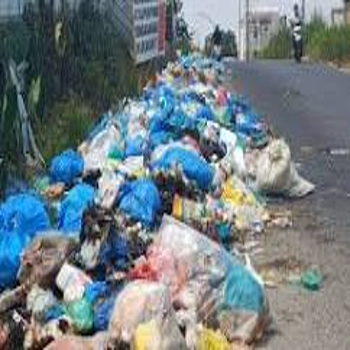

MobileNetV2: Plastik (97.31%)
VGG16: Plastik (99.97%)
Saran: Bersihkan plastik sebelum dimasukkan ke tempat daur ulang.
\nTop-3 MobileNetV2:
Plastik 97.31%
Medis 2.58%
nonsampah 0.07%
\nTop-3 VGG16:
Plastik 99.97%
Medis 0.02%
nonsampah 0.01%
{'mobilenetv2': {'class': 'Plastik', 'confidence': 97.31}, 'vgg16': {'class': 'Plastik', 'confidence': 99.97}}


In [81]:
recycle_info = {
    "B3": {"status": "Limbah berbahaya", "advice": "Simpan di tempat khusus dan jangan dibuang sembarangan."},
    "Kaca": {"status": "Bisa didaur ulang", "advice": "Pisahkan kaca berdasarkan warna sebelum didaur ulang."},
    "Kardus": {"status": "Bisa didaur ulang", "advice": "Lipat kardus agar menghemat ruang penyimpanan."},
    "Kertas": {"status": "Bisa didaur ulang", "advice": "Pastikan kertas kering dan bersih sebelum didaur ulang."},
    "Logam": {"status": "Bisa didaur ulang", "advice": "Logam dapat dijual ke pengepul untuk didaur ulang."},
    "Medis": {"status": "Limbah medis", "advice": "Gunakan penanganan khusus untuk limbah medis."},
    "nonsampah": {"status": "Bukan sampah daur ulang", "advice": "Objek tidak termasuk kategori sampah yang dapat diproses."},
    "organik": {"status": "Sampah organik", "advice": "Dapat diolah menjadi kompos atau pupuk organik."},
    "Plastik": {"status": "Bisa didaur ulang", "advice": "Bersihkan plastik sebelum dimasukkan ke tempat daur ulang."}
}

def get_recycle_advice(label):
    # Fallback jika nama kelas dataset berbeda kapitalisasi/penamaan.
    if label in recycle_info:
        return recycle_info[label]
    key = label.lower()
    aliases = {
        "hazardous waste": "B3", "kaca": "Kaca", "glass": "Kaca",
        "cardboard": "Kardus", "kardus": "Kardus", "paper": "Kertas",
        "kertas": "Kertas", "metal": "Logam", "logam": "Logam",
        "medical waste": "Medis", "medis": "Medis", "plastic": "Plastik",
        "plastik": "Plastik", "organic waste": "organik", "organik": "organik",
        "non-waste": "nonsampah", "non-waste items": "nonsampah"
    }
    mapped = aliases.get(key)
    return recycle_info.get(mapped, {"status": "Kategori terdeteksi", "advice": "Periksa panduan pemilahan lokal."})

def predict_image_comparison(img_path):
    raw = Image.open(img_path).convert("RGB")
    display(raw.resize((350, 350)))

    arr = np.asarray(raw.resize(IMAGE_SIZE), dtype=np.float32)[None, ...]
    pred_m = mobilenet_model.predict(mobilenet_preprocess(arr.copy()), verbose=0)[0]
    pred_v = vgg_model.predict(vgg_preprocess(arr.copy()), verbose=0)[0]

    idx_m, idx_v = int(np.argmax(pred_m)), int(np.argmax(pred_v))
    label_m, label_v = class_names[idx_m], class_names[idx_v]
    print("MobileNetV2:", label_m, f"({pred_m[idx_m]*100:.2f}%)")
    print("VGG16:", label_v, f"({pred_v[idx_v]*100:.2f}%)")
    print("Saran:", get_recycle_advice(label_m)["advice"])

    print("\\nTop-3 MobileNetV2:")
    for i in np.argsort(pred_m)[-3:][::-1]:
        print(class_names[i], f"{pred_m[i]*100:.2f}%")
    print("\\nTop-3 VGG16:")
    for i in np.argsort(pred_v)[-3:][::-1]:
        print(class_names[i], f"{pred_v[i]*100:.2f}%")

    return {
        "mobilenetv2": {"class": label_m, "confidence": round(float(pred_m[idx_m]*100), 2)},
        "vgg16": {"class": label_v, "confidence": round(float(pred_v[idx_v]*100), 2)}
    }

print("Upload satu gambar untuk prediksi (opsional).")
uploaded_image = files.upload()
if uploaded_image:
    image_name = next(iter(uploaded_image))
    prediction_result = predict_image_comparison(image_name)
    print(prediction_result)
else:
    print("Tidak ada gambar diunggah; tahap inference interaktif dilewati.")

CELL 25 — Ringkasan eksperimen, metadata, dan arsip hasil

In [82]:
# Isi metadata berdasarkan sumber dataset dan kondisi eksperimen.
# Informasi yang belum diverifikasi tidak boleh ditebak atau dikarang.

EXPERIMENT_METADATA = {
    "dataset_source_name": "Dataset Klasifikasi Sampah",
    "dataset_source_url_or_reference": (
        "https://www.kaggle.com/datasets/auliarashad/dataset-klasifikasi-sampah"
    ),
    "dataset_collection_description": (
        "The dataset was obtained from the Kaggle repository "
        "'Dataset Klasifikasi Sampah' by auliarashad. "
        "It contains digital images categorized into nine waste classes. "
        "The images were used for waste image classification after "
        "the dataset preprocessing and cleaning procedures described "
        "in this experiment. Specific image variations, such as lighting, "
        "viewpoint, background, and object condition, should be described "
        "based on direct inspection of the dataset."
    ),

    "gpu_runtime": [
        d.name for d in tf.config.list_physical_devices("GPU")
    ],
    "tensorflow_version": tf.__version__,
    "seed": SEED,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "split_ratio": "70:20:10",
    "augmentation": AUGMENTATION_CONFIG,
    "class_weight_formula": "w_c = N / (K * n_c)",
    "tuner_trials_per_model": TUNER_TRIALS,
    "tuner_epochs": TUNER_EPOCHS,
    "tuner_steps_per_epoch": TUNER_STEPS,
    "phase1_max_epochs": PHASE1_EPOCHS,
    "phase2_max_epochs": PHASE2_EPOCHS,
    "auc_method": "Multiclass One-vs-Rest, macro average"
}

with open(
    os.path.join(DIRS["results"], "experiment_metadata.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(EXPERIMENT_METADATA, f, indent=2, ensure_ascii=False)

print("=" * 80)
print("FINAL EXPERIMENT SUMMARY")
print("=" * 80)

print(df_overall.to_string(index=False))

print("\nEfficiency:")
print(efficiency.to_string(index=False))

print("\nDataset counts:", split_counts)
print("\nSemua hasil tersimpan di:", DRIVE_PATH)


# Zip hasil utama (tidak memasukkan folder checkpoint besar agar arsip tetap ringkas).
zip_output = os.path.join(DRIVE_PATH, "hasil_komparatif_revisi.zip")

if os.path.exists(zip_output):
    os.remove(zip_output)

with zipfile.ZipFile(
    zip_output,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zf:

    # Masukkan seluruh file hasil eksperimen.
    for root, dirs, filenames in os.walk(DIRS["results"]):
        for filename in filenames:
            full = os.path.join(root, filename)

            zf.write(
                full,
                arcname=os.path.relpath(full, DRIVE_PATH)
            )

    # Masukkan model dan file ekspor utama jika tersedia.
    for filename in [
        "best_mobilenetv2.keras",
        "best_vgg16.keras",
        "class_names.json",
        "mobilenetv2_optimized.tflite",
        "vgg16_optimized.tflite"
    ]:
        full = os.path.join(DIRS["exports"], filename)

        if os.path.isfile(full):
            zf.write(
                full,
                arcname=os.path.relpath(full, DRIVE_PATH)
            )

print("Arsip hasil:", zip_output)

FINAL EXPERIMENT SUMMARY
      Model  Accuracy  Precision_macro  Recall_macro  F1_macro  Precision_weighted  Recall_weighted  F1_weighted  AUC_OvR_macro  Top3_accuracy
MobileNetV2  0.918367         0.906721      0.913391  0.908824            0.920883         0.918367     0.918464       0.994829       0.988226
      VGG16  0.937991         0.928860      0.933278  0.930636            0.939023         0.937991     0.938121       0.996385       0.991366
\nEfficiency:
      Model  Total_parameters  Param_memory_MB_fp32  Weights_file_MB  Keras_file_MB  GFLOPs_per_image  Inference_mean_ms_per_image  Inference_median_ms_per_image  Inference_std_ms  Inference_p95_ms  Throughput_bs16_img_per_s  GPU_peak_delta_MB_bs1
MobileNetV2           2274633              8.677036        22.364510      22.508106          0.612760                     5.290353                       5.240244          0.283901          5.642575                 634.645507              13.821777
      VGG16          14984009       

Checklist bukti revisi reviewer
Cell terakhir ini memeriksa keberadaan beberapa file hasil. Status file yang ada bukan pengganti pemeriksaan isi dan interpretasi ilmiah.

In [83]:
# Ringkasan ketersediaan artefak untuk menyiapkan revisi manuskrip
_review_files = {
    "Distribusi dataset sebelum/sesudah cleaning": "dataset_before_after_cleaning.csv",
    "Distribusi kelas final": "dataset_final_distribution.csv",
    "Distribusi train/validation/test": "split_class_distribution.csv",
    "Bobot kelas": "class_weights.csv",
    "Metrik test keseluruhan": "overall_test_metrics.csv",
    "Metrik per kelas": "per_class_metrics.csv",
    "Detail AUC": "auc_detail.csv",
    "AUC per kelas": "auc_per_class.csv",
    "Confusion matrix / analisis kesalahan": "hardest_classes.csv",
    "Efisiensi komputasi": "model_efficiency.csv",
    "Ablation": "ablation_results_both_models.csv",
    "Ablation validation summary": "ablation_validation_summary.csv",
    "Benchmark TFLite CPU": "tflite_efficiency.csv",
}

_review_status = []
for _label, _filename in _review_files.items():
    _full = os.path.join(DIRS["results"], _filename)
    _review_status.append({
        "Bukti": _label,
        "File": _filename,
        "Status": "TERSEDIA" if os.path.isfile(_full) else "BELUM TERSEDIA"
    })

df_reviewer_evidence = pd.DataFrame(_review_status)
display(df_reviewer_evidence)
df_reviewer_evidence.to_csv(
    os.path.join(DIRS["results"], "reviewer_evidence_checklist.csv"),
    index=False
)

print(
    "Catatan: metadata sumber dataset pada EXPERIMENT_METADATA harus diisi "
    "berdasarkan sumber asli. Jangan mengirim placeholder seperti "
    "'ISI NAMA/SUMBER DATASET' ke manuskrip."
)


,Bukti,File,Status
0,Distribusi dataset sebelum/sesudah cleaning,dataset_before_after_cleaning.csv,TERSEDIA
1,Distribusi kelas final,dataset_final_distribution.csv,TERSEDIA
2,Distribusi train/validation/test,split_class_distribution.csv,TERSEDIA
3,Bobot kelas,class_weights.csv,TERSEDIA
4,Metrik test keseluruhan,overall_test_metrics.csv,TERSEDIA
5,Metrik per kelas,per_class_metrics.csv,TERSEDIA
6,Detail AUC,auc_detail.csv,TERSEDIA
7,AUC per kelas,auc_per_class.csv,TERSEDIA
8,Confusion matrix / analisis kesalahan,hardest_classes.csv,TERSEDIA
9,Efisiensi komputasi,model_efficiency.csv,TERSEDIA


Catatan: metadata sumber dataset pada EXPERIMENT_METADATA harus diisi berdasarkan sumber asli. Jangan mengirim placeholder seperti 'ISI NAMA/SUMBER DATASET' ke manuskrip.


In [22]:
import pandas as pd
import os

path = os.path.join(
    DIRS["results"],
    "ablation_validation_only.csv"
)

df = pd.read_csv(path)

print("Jumlah eksperimen tersimpan:", len(df))
display(df)

Jumlah eksperimen tersimpan: 8


,Model,Seed,Augmentation,Class_weighting,Condition,Epochs_run,Best_epoch_val_loss,Best_val_loss,Minority_classes,Val_accuracy,...,Recall_B3,Recall_Kaca,Recall_Kardus,Recall_Kertas,Recall_Logam,Recall_Medis,Recall_Plastik,Recall_nonsampah,Recall_organik,Train_minutes
0,mobilenetv2,42,True,True,augmentation_yes_weight_yes,15,15,0.338426,"organik, B3, Kardus",0.894819,...,0.921875,0.927602,0.891626,0.803324,0.900826,0.858921,0.832669,0.945758,0.957627,33.89
1,mobilenetv2,42,True,False,augmentation_yes_weight_no,15,15,0.316876,"organik, B3, Kardus",0.903454,...,0.921875,0.927602,0.862069,0.839335,0.904959,0.846473,0.828685,0.973574,0.940678,33.56
2,mobilenetv2,42,False,True,augmentation_no_weight_yes,15,15,0.310730,"organik, B3, Kardus",0.899529,...,0.927083,0.923077,0.891626,0.800554,0.880165,0.871369,0.872510,0.949930,0.974576,8.20
3,mobilenetv2,42,False,False,augmentation_no_weight_no,15,15,0.296176,"organik, B3, Kardus",0.906593,...,0.916667,0.914027,0.886700,0.822715,0.880165,0.863071,0.860558,0.979138,0.966102,8.18
4,vgg16,42,True,True,augmentation_yes_weight_yes,15,15,0.285374,"organik, B3, Kardus",0.921900,...,0.927083,0.932127,0.906404,0.864266,0.900826,0.908714,0.880478,0.965229,0.991525,36.57
5,vgg16,42,True,False,augmentation_yes_weight_no,15,15,0.301324,"organik, B3, Kardus",0.917582,...,0.937500,0.914027,0.911330,0.858726,0.892562,0.871369,0.872510,0.973574,0.983051,37.28
6,vgg16,42,False,True,augmentation_no_weight_yes,15,14,0.267776,"organik, B3, Kardus",0.929356,...,0.942708,0.945701,0.931034,0.858726,0.888430,0.929461,0.892430,0.972184,0.991525,13.83
7,vgg16,42,False,False,augmentation_no_weight_no,15,11,0.263986,"organik, B3, Kardus",0.930926,...,0.932292,0.932127,0.891626,0.900277,0.888430,0.887967,0.908367,0.983310,0.991525,13.86
